# 16_zenteno_recalibration_legacy_treatment_variable_solubility

Copy of 16_zenteno_recalibration_legacy_treatment.source.ipynb. Original files are preserved. Chemical model and preprocessing remain unchanged. Gas calibration below replaces the previous constant-solubility parameters.


## Variable CO₂ solubility and gas recalibration
Chemical parameters, samples, initial conditions, nutrient pulses and the 5–10 g/L activation are preserved. Only kLa and observation gain are fitted, independently for each chemical model. Training: LAB019–021; holdout: LAB016–018. The objective is ordinary MSE with equal weight per training LAB, using the original hourly RAW medians (not the Kalman-filter 30-minute means).

The empirical wine correlation reproduced as Eq. 1 in Liger-Belair et al. (2023), attributed there to Lonvaud-Funel and Matsumoto, is
\[
k_H=3.295\exp[(7\times10^{-5}a-0.02905)T-0.0179a-0.00111S],\qquad C_{sat}=k_Hp_{CO_2}.
\]
T is in °C, a is ethanol % vol, S is glucose + fructose in g/L, kH is in g/(L bar). Ethanol conversion uses a=E/7.8924, with pure ethanol density 789.24 g/L at 20°C as a reference conversion, not an evolving mixture density. Measured temperature and model-predicted ethanol/sugar vary throughout each batch. Coefficients are fixed; pCO2=1 bar is an explicit assumption, not a pressure measurement. Application to fermenting must is an extrapolation requiring validation, particularly at high sugar. Source: https://doi.org/10.1021/acsomega.3c01812 . The historical provisional correlation is not used.

The transfer law below is our adaptation, not an equation attributed to that paper:
\[
q_{eff}=Aq_{prod},\quad r_{abs}=\min(q_{eff},k_La\max(C_{sat}-C_d,0)),\quad
r_{des}=k_La\max(C_d-C_{sat},0),\quad
\dot C_d=r_{abs}-r_{des},\quad q_{gas}=q_{eff}-\dot C_d,\quad q_{pred}=gq_{gas}.
\]
This retains the previous absorption-limited reservoir and adds release above equilibrium. Cd is not clipped to changing saturation: supersaturation can persist and relax. Cd(0)=0 is retained. The same effective source activation is retained, so conservation applies to that source, not to unattenuated stoichiometric production. kLa is an effective coefficient in this adapted law, not an independently measured physical transfer coefficient.

Exact piecewise integration for interval-constant midpoint saturation and interval-mean production preserves positivity and concentration balance. Finite-volume mass checks include homogeneous withdrawals; gain is outside the balance. Positive fitting bounds are kLa=[0.001,20] h⁻¹, gain=[0.05,3], declared exploratory constraints. A log-spaced kLa profile with analytically optimized bounded gain, local refinement, bound checks and half-step verification is reported. Holdout never selects parameters.


In [1]:
from pathlib import Path
from dataclasses import replace
import sys,json,hashlib,math,time
import numpy as np,pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares,minimize_scalar
from IPython.display import display
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/wine_fermentation').is_dir())
assert Path(sys.prefix).name.lower()=='fermentation'
sys.path.insert(0,str(ROOT/'src'));sys.dont_write_bytecode=True
from wine_fermentation import model as kin
from wine_fermentation.data import natural_batches
from wine_fermentation.models.historical.calibration import load
from wine_fermentation.comparison import observations,chemical_observations,CHEMICAL_COLUMNS
NAME='16_zenteno_recalibration_legacy_treatment_variable_solubility'
protected=[p for folder in ['src','configs','data/compatibility/chemistry','data/cleaned/natural/lab004_009','notebooks'] for p in (ROOT/folder).rglob('*') if p.is_file() and '__pycache__' not in str(p) and '_variable_solubility.' not in p.name]
hashes={p:hashlib.sha256(p.read_bytes()).hexdigest() for p in protected}
data,training,profiles=natural_batches(ROOT)
# Correcciones de recuento inicial indicadas por el usuario; originales conservados.
INITIAL_VIABLE_MCELLS_ML={'LAB004':10.75,'LAB005':11.25}
initial_biomass_audit=[];corrected_training=[]
for batch in training:
 if batch.batch in INITIAL_VIABLE_MCELLS_ML:
  count=INITIAL_VIABLE_MCELLS_ML[batch.batch];x0=count*.03
  ids=np.flatnonzero(np.isclose(batch.time,0.));assert len(ids)==1
  obs0={k:v.copy() for k,v in batch.observations.items()};obs0['X'][ids[0]]=x0
  initial_biomass_audit.append(dict(LAB=batch.batch,original_g_L=batch.initials['X'],viables_millones_mL=count,corregido_g_L=x0))
  batch=replace(batch,initials={**batch.initials,'X':x0},observations=obs0)
  mask=data.batch.eq(batch.batch)&np.isclose(data.time_h,0.)
  assert mask.sum()==1
  data.loc[mask,'X_viable_kg_m3']=x0;data.loc[mask,'X_viable_mcells_ml']=count
  assert batch.initials['X']==batch.observations['X'][ids[0]]
 corrected_training.append(batch)
training=corrected_training
assert len(initial_biomass_audit)==2
display(pd.DataFrame(initial_biomass_audit))

start=kin.normalize_parameters(json.loads((ROOT/'configs/theta/theta_full.json').read_text()))
config=json.loads((ROOT/'configs/models/without_transporters/calibration.json').read_text())
# Tabla 2 de Zenteno: Kn=0.01 g/L a23C; nuestro Kn0 se referencia a20C.
KN_ZENTENO_G_L=0.01;KN_PAPER_REF_K=296.15;KN_CODE_REF_K=293.15
KN_THERMAL_FACTOR=np.exp(kin.FIXED_CONSTANTS['EaKn']*(KN_PAPER_REF_K-KN_CODE_REF_K)/(KN_CODE_REF_K*kin.FIXED_CONSTANTS['R']*KN_PAPER_REF_K))
start['Kn0']=KN_ZENTENO_G_L/KN_THERMAL_FACTOR
KD0_ZENTENO_H=0.00044
start['Kd0']=KD0_ZENTENO_H
assert np.isclose(start['Kn0']*KN_THERMAL_FACTOR,KN_ZENTENO_G_L,rtol=1e-14)
display(pd.Series(dict(Kn_Zenteno_g_L=KN_ZENTENO_G_L,referencia_paper_C=23,Kn0_codigo_g_L=start['Kn0'],referencia_codigo_C=20),name='Kn fijo y conversión de referencia térmica'))
names=[k for k in config['bounds'] if k not in ['aN','KNa','Kn0','Kd0']]
assert len(names)==8 and 'Kn0' not in names and 'Kd0' not in names
bounds={k:config['bounds'][k] for k in names};lo,hi=np.array(list(bounds.values())).T
fixed={k:v for k,v in start.items() if k not in names}
display(pd.Series(fixed,name='Fijos: theta_full salvo Kn y Kd0 de Zenteno'))
display(pd.DataFrame([dict(parametro=k,inicio=start[k],inicio_factible=np.clip(start[k],lo[i]+1e-10,hi[i]-1e-10),minimo=lo[i],maximo=hi[i]) for i,k in enumerate(names)]))


,LAB,original_g_L,viables_millones_mL,corregido_g_L
0,LAB004,0.3939,10.75,0.3225
1,LAB005,0.4932,11.25,0.3375


Kn_Zenteno_g_L          0.010000
referencia_paper_C     23.000000
Kn0_codigo_g_L          0.008258
referencia_codigo_C    20.000000
Name: Kn fijo y conversión de referencia térmica, dtype: float64

Kn0     0.008258
Kg0     4.400775
Kf0    19.296084
Kd0     0.000440
Yxg     0.966094
Yxf     1.109896
m0      0.018339
Name: Fijos: theta_full salvo Kn y Kd0 de Zenteno, dtype: float64

,parametro,inicio,inicio_factible,minimo,maximo
0,mu0,0.078728,0.078728,0.05,1.0000
1,betaG0,0.428878,0.428878,0.10,10.0000
2,betaF0,3.440399,3.440399,0.10,10.0000
3,Kig0,17.845213,17.845213,5.00,1000.0000
4,Kie0,24.895476,24.895476,5.00,1000.0000
5,Yxn,3.734653,3.734653,1.00,100.0000
6,Yeg,0.250395,0.250395,0.10,0.5114
7,Yef,0.684927,0.511400,0.10,0.5114


## Auditoría de observaciones y ponderación
Sólo se modifican en memoria los objetivos de YAN. Las figuras separan muestras originales, utilizadas y excluidas. Los huecos siguen ausentes. Las iniciales son entradas y no puntúan. Las réplicas para estimar sigmaX son004/005 y007/008 a tiempos coincidentes; no se emplean datos de validación.


In [2]:
diffs=[]
bylab={b.batch:b for b in training}
for a,b in [('LAB004','LAB005'),('LAB007','LAB008')]:
 aa=pd.Series(bylab[a].observations['X'],index=bylab[a].time);bb=pd.Series(bylab[b].observations['X'],index=bylab[b].time)
 z=pd.concat([aa,bb],axis=1).dropna();diffs.extend((z.iloc[:,0]-z.iloc[:,1]).tolist())
sigma_rep=float(np.sqrt(np.mean(np.square(diffs)))/np.sqrt(2));SIGMA_X=max(.5,3*sigma_rep)
assert len(diffs)>0
print('Pares de réplicas:',len(diffs),'sigma réplica:',sigma_rep,'sigmaX aplicada:',SIGMA_X)
treated=[];audit=[];rules=[]
for b in training:
 obs={k:v.copy() for k,v in b.observations.items()};old=obs['N'].copy()
 obs['N'][np.isfinite(old)&(old<=.020)]=0
 if b.batch=='LAB006':
  ids=np.flatnonzero(np.isclose(b.time,122)&np.isfinite(old));assert len(ids)==1 and np.isclose(old[ids[0]],.027)
  obs['N'][ids]=0;depletion=122.
 else:
  last=max(t for t,d in b.pulses['N']);ids=np.flatnonzero((b.time>=last)&np.isfinite(obs['N'])&(obs['N']==0));assert len(ids)
  depletion=float(b.time[ids[0]])
 obs['N'][b.time>depletion+12]=np.nan
 for i in np.flatnonzero(np.isfinite(old)):
  audit.append(dict(LAB=b.batch,t_h=b.time[i],original_mg=old[i]*1000,usado_mg=obs['N'][i]*1000,estado='Inicial' if b.time[i]==0 else ('Excluido' if not np.isfinite(obs['N'][i]) else ('Transformado' if old[i]!=obs['N'][i] else 'Usado'))))
 assert all(np.array_equal(obs[k],b.observations[k],equal_nan=True) for k in obs if k!='N')
 treated.append(replace(b,observations=obs))
 rules.append(dict(LAB=b.batch,agotamiento_h=depletion,corte_YAN_h=depletion+12,N0_mg=b.initials['N']*1000,pulsos=b.pulses['N'],**{k:int(np.count_nonzero(np.isfinite(obs[k])&(b.time>0))) for k in obs}))
audit=pd.DataFrame(audit);display(pd.DataFrame(rules));display(audit)
def sigma(state,y):return np.full_like(y,SIGMA_X) if state=='X' else kin.sigma_for_state(state,y)
def simulate(b,p):
 def rhs(t,y):
  out=np.asarray(kin.rhs(t,y,p,b))
  if y[2]<=0 or y[3]<=0:
   q=kin.kinetic_terms(p,kin.temperature_at(b,t),*y);growth=q['mu']*max(float(y[0]),0)
   out[0]-=growth;out[1]+=growth/p['Yxn'];out[2]+=growth/p['Yxg'];out[3]+=growth/p['Yxf']
  return out
 # Muestra previa al salto si coincide con la nutrición; dosis completa después.
 minimum=np.full(5,np.inf);jumps=[];events={}
 for tp,dose in b.pulses.get('N',()):
  assert tp>float(b.time[0]) and dose>=0,'No se admiten pulsos iniciales extra'
  if tp<=b.time[-1]:events[float(tp)]=events.get(float(tp),0.)+float(dose)
 times=np.asarray(b.time);state=kin.initial_vector(b);records={float(times[0]):state.copy()};now=float(times[0])
 for end in sorted(set([float(times[-1])]+list(events))):
  requested=times[(times>now)&(times<=end)]
  sol=solve_ivp(rhs,(now,end),state,t_eval=np.unique(np.r_[requested,end]),method='LSODA',rtol=2e-6,atol=2e-8,max_step=.5)
  if not sol.success or not np.isfinite(sol.y).all() or np.any(sol.y.min(axis=1)<-np.array([1e-6,1e-6,1e-4,1e-4,1e-6])):raise RuntimeError('Integración química inválida '+b.batch+' '+str(sol.message)+' mínimos='+str(dict(zip(kin.STATE_NAMES,sol.y.min(axis=1)))))
  minimum=np.minimum(minimum,sol.y.min(axis=1))
  records.update({float(t):y.copy() for t,y in zip(sol.t,sol.y.T)});state=sol.y[:,-1].copy();now=end
  if end in events:
   before=state.copy();state[1]+=events[end]
   assert np.isclose(state[1]-before[1],events[end],atol=1e-12) and np.array_equal(state[[0,2,3,4]],before[[0,2,3,4]])
   jumps.append(dict(t=end,dose=events[end],before=before.copy(),after=state.copy()))
 f=pd.DataFrame(np.maximum(np.vstack([records[float(t)] for t in times]),0),index=times,columns=kin.STATE_NAMES);f['GF']=f.G+f.F
 f.attrs['minimum_integrated_states']=dict(zip(kin.STATE_NAMES,minimum.tolist()))
 f.attrs['pulse_jumps']=jumps
 assert np.isclose(sum(j['dose'] for j in jumps),sum(events.values()),atol=1e-12)
 return f

def with_jumps(f):
 extra=[];tt=[]
 for j in f.attrs['pulse_jumps']:
  if j['t'] not in f.index:extra.append(j['before']);tt.append(j['t'])
  extra.append(j['after']);tt.append(j['t'])
 if not extra:return f
 added=pd.DataFrame(extra,index=tt,columns=kin.STATE_NAMES);added['GF']=added.G+added.F
 return pd.concat([f,added]).sort_index(kind='stable')

support=[(b,s,np.isfinite(b.observations[s])&(b.time>0)) for b in treated for s in kin.STATE_NAMES]
NR=sum(m.sum() for b,s,m in support);calls=0;rejected=0


Pares de réplicas: 23 sigma réplica: 0.1189341469231937 sigmaX aplicada: 0.5


,LAB,agotamiento_h,corte_YAN_h,N0_mg,pulsos,X,N,G,F,E
0,LAB004,91.0,103.0,230.76,"((68.5, 0.08),)",10,8,12,12,4
1,LAB005,91.0,103.0,227.30,"((68.5, 0.08),)",10,8,12,12,4
2,LAB006,122.0,134.0,229.12,"((100.0, 0.08),)",12,9,14,14,4
3,LAB007,88.0,100.0,239.04,"((65.5, 0.08),)",11,8,12,12,5
4,LAB008,88.0,100.0,239.22,"((65.5, 0.08),)",11,8,12,12,5
5,LAB009,64.0,76.0,237.40,"((41.84615384615385, 0.08),)",10,6,11,11,4


,LAB,t_h,original_mg,usado_mg,estado
0,LAB004,0.0,230.76,230.76,Inicial
1,LAB004,19.0,182.72,182.72,Usado
2,LAB004,26.0,157.42,157.42,Usado
3,LAB004,43.0,60.16,60.16,Usado
4,LAB004,50.0,19.00,0.00,Transformado
...,...,...,...,...,...
74,LAB009,88.0,17.00,NaN,Excluido
75,LAB009,96.0,19.00,NaN,Excluido
76,LAB009,120.0,5.00,NaN,Excluido
77,LAB009,144.0,25.00,NaN,Excluido


## Fixed chemical calibration
The previously calibrated chemical parameters are retained exactly. Only the gas layer is recalibrated in this notebook.


In [3]:
# Química congelada de la recalibración anterior; sin optimización en esta prueba.
theta={'mu0': 0.09403147367985473, 'betaG0': 0.42243676903335664, 'betaF0': 0.6236552480900203, 'Kn0': 0.008257860224319971, 'Kg0': 4.400775419123265, 'Kf0': 19.296083508118652, 'Kig0': 65.01993873457147, 'Kie0': 96.26516563486751, 'Kd0': 0.00044, 'Yxn': 6.456225797038313, 'Yxg': 0.9660935553477866, 'Yxf': 1.1098958529485594, 'Yeg': 0.4684585383875136, 'Yef': 0.5113278649826252, 'm0': 0.0183385793928771}
assert theta['Kn0']==start['Kn0'] and theta['Kd0']==KD0_ZENTENO_H
assert all(theta[k]==v for k,v in fixed.items())
print('PARÁMETROS QUÍMICOS COMPLETOS',json.dumps(theta,indent=2))
print('Química fija: no se recalibra en esta prueba de activación.')
traincurves={b.batch:simulate(b,theta) for b in treated}


PARÁMETROS QUÍMICOS COMPLETOS {
  "mu0": 0.09403147367985473,
  "betaG0": 0.42243676903335664,
  "betaF0": 0.6236552480900203,
  "Kn0": 0.008257860224319971,
  "Kg0": 4.400775419123265,
  "Kf0": 19.296083508118652,
  "Kig0": 65.01993873457147,
  "Kie0": 96.26516563486751,
  "Kd0": 0.00044,
  "Yxn": 6.456225797038313,
  "Yxg": 0.9660935553477866,
  "Yxf": 1.1098958529485594,
  "Yeg": 0.4684585383875136,
  "Yef": 0.5113278649826252,
  "m0": 0.0183385793928771
}
Química fija: no se recalibra en esta prueba de activación.


## Muestras de entrenamiento: originales, usadas y excluidas
Círculos negros: dato usado sin transformación; cuadrados verdes: YAN transformado a cero; cruces naranjas: dato excluido; círculos grises vacíos: valor original transformado. Iniciales azules vacías. La predicción se compara con el soporte realmente entregado al optimizador.


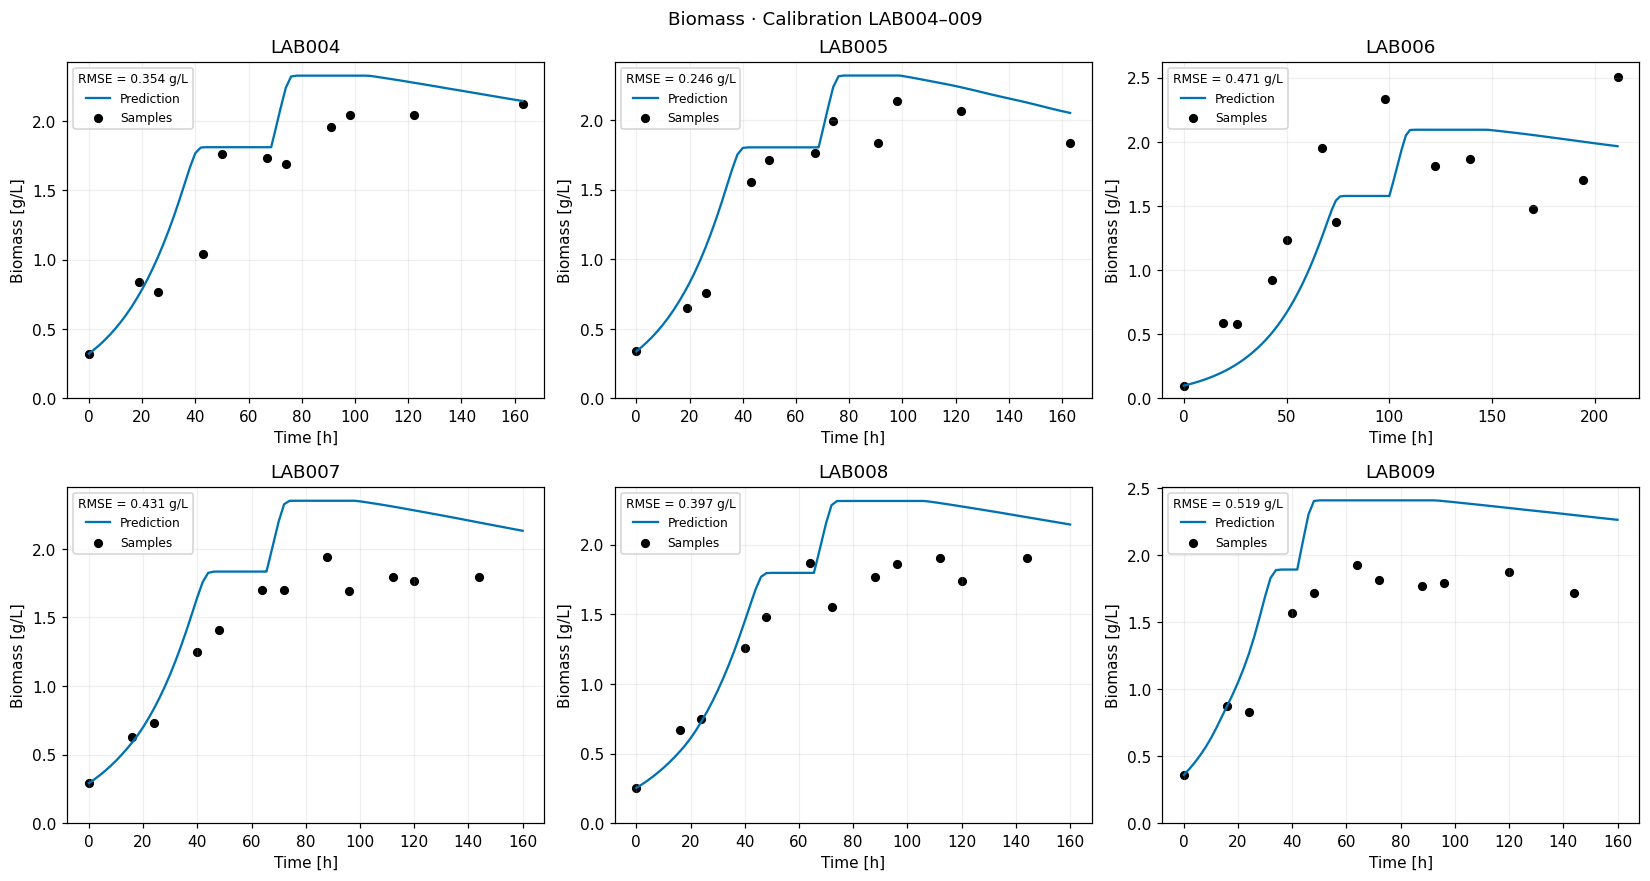

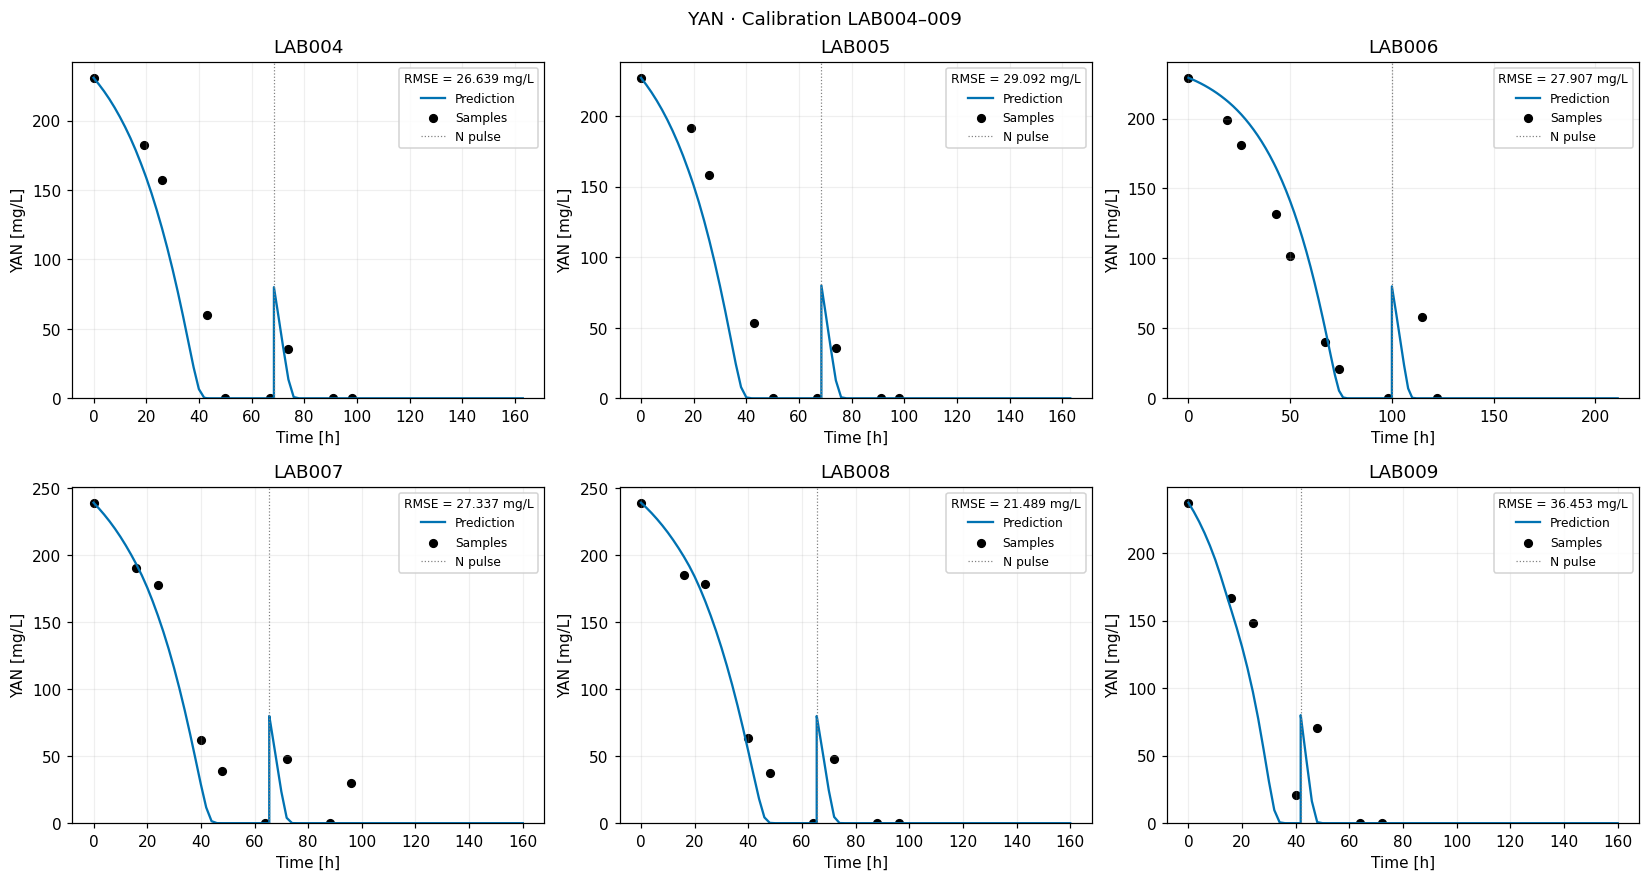

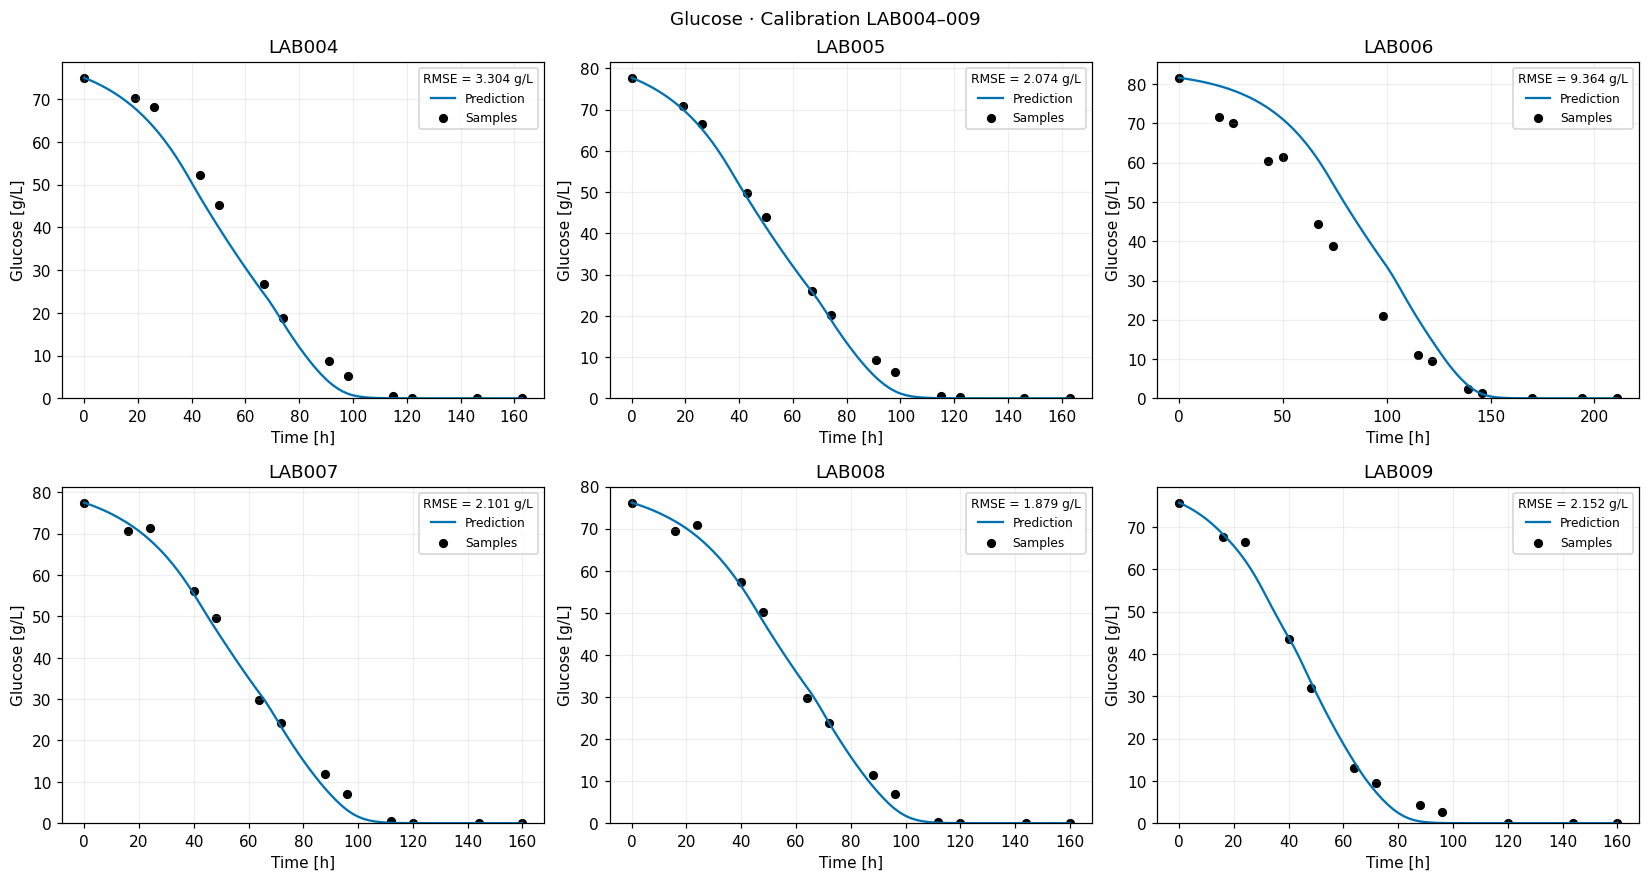

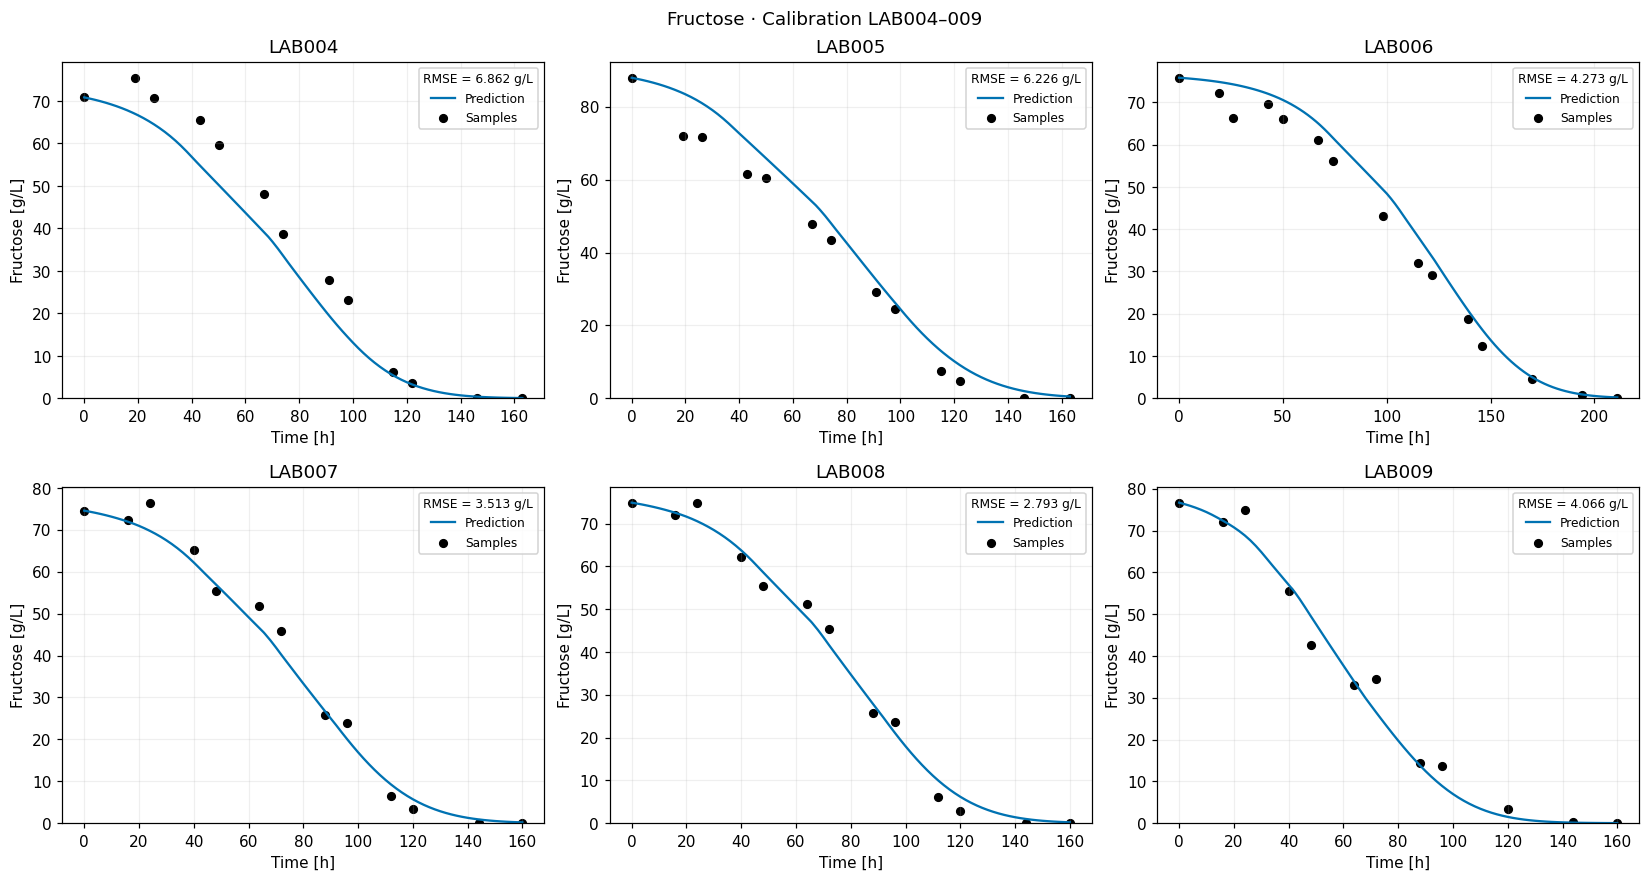

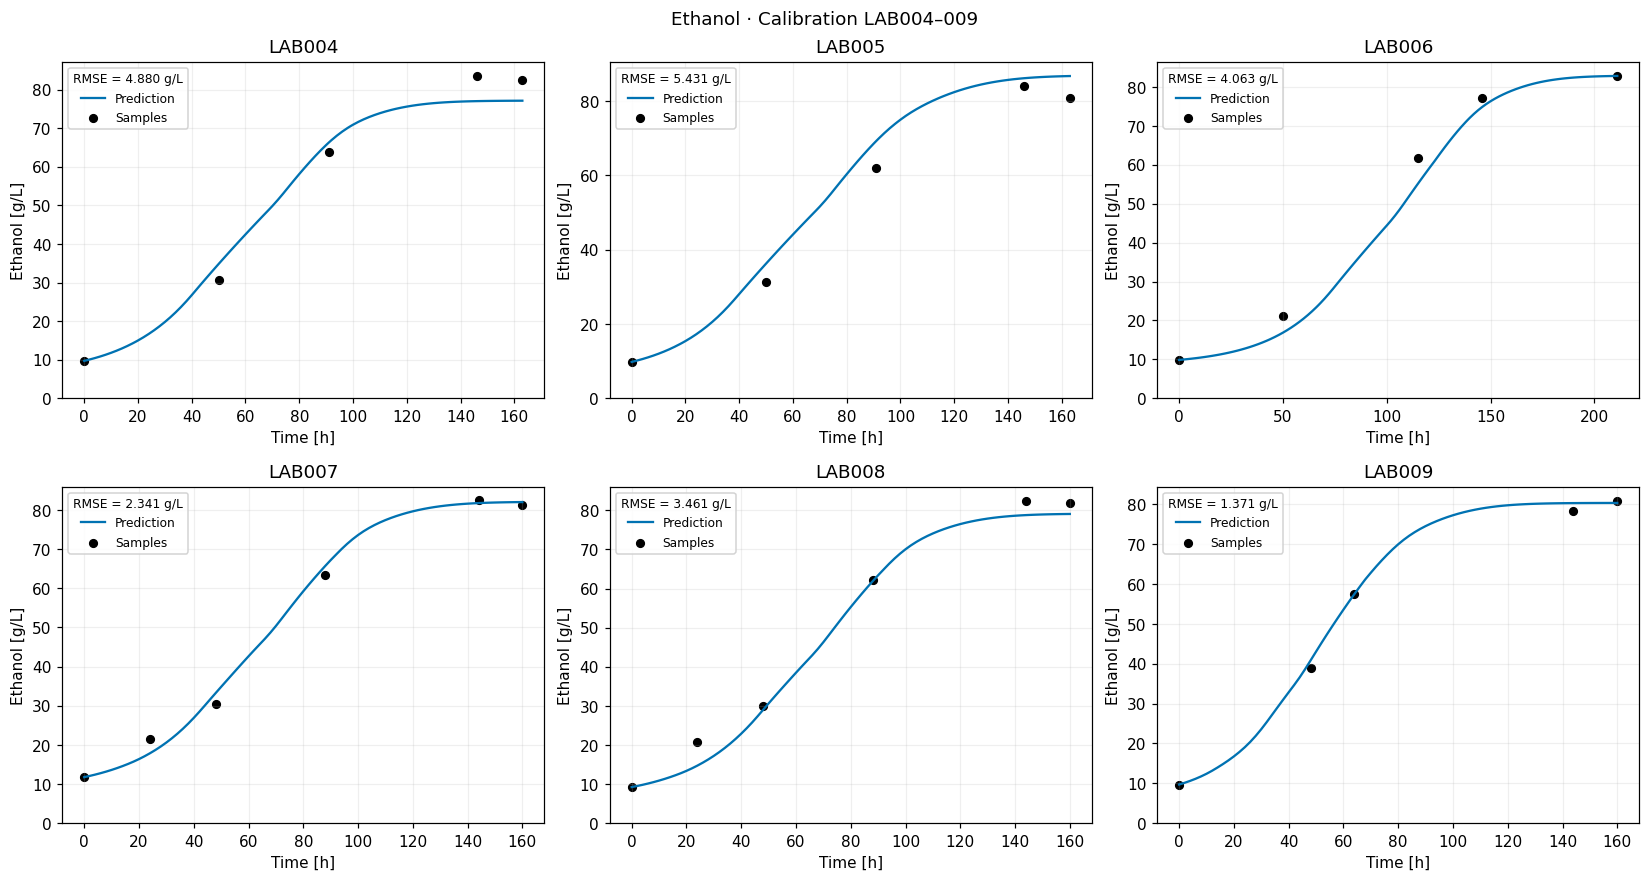

In [4]:
def legend_inside(ax):
 handles,labels=ax.get_legend_handles_labels()
 unique=dict(zip(labels,handles))
 legend=ax.legend(unique.values(),unique.keys(),loc='best',fontsize=8,framealpha=.85,title=getattr(ax,'_rmse_text',None),title_fontsize=8)
 assert len(legend.get_texts())==len(unique)

for s,title,scale in [('X','Biomass',1),('N','YAN',1000),('G','Glucose',1),('F','Fructose',1),('E','Ethanol',1)]:
 fig,axs=plt.subplots(2,3,figsize=(15,8));items={}
 for ax,b in zip(axs.flat,treated):
  new=b.observations[s];used=np.isfinite(new)&(b.time>0)
  pf=with_jumps(traincurves[b.batch]);ax.plot(pf.index,pf[s]*scale,label='Prediction',c='#0072B2')
  ax.scatter(b.time[used],new[used]*scale,c='black',s=25,label='Samples')
  initial_point=ax.scatter([0.],[b.initials[s]*scale],c='black',s=25,label='Samples')
  assert np.allclose(initial_point.get_offsets(),[[0.,b.initials[s]*scale]])
  residual=(traincurves[b.batch][s].to_numpy()[used]-new[used])*scale
  if len(residual):ax._rmse_text=f"RMSE = {np.sqrt(np.mean(residual**2)):.3f} {'mg/L' if s=='N' else 'g/L'}"
  if s=='N':
   for t,d in b.pulses['N']:ax.axvline(t,c='gray',ls=':',lw=.8,label='N pulse')
  ax.set(title=b.batch,xlabel='Time [h]',ylabel=title+(' [mg/L]' if s=='N' else ' [g/L]'),ylim=(0,None));ax.grid(alpha=.2)
  for h,l in zip(*ax.get_legend_handles_labels()):items[l]=h
 expected={'Prediction','Samples'}|({'N pulse'} if s=='N' else set());assert set(items)==expected
 fig.suptitle(title+' · Calibration LAB004–009',y=.99);fig.tight_layout(pad=.7,h_pad=1.2,w_pad=.9);[legend_inside(ax) for ax in axs.flat];assert not fig.legends;plt.show()


## Scope
Chemical equations and preprocessing are inherited from the original. The variable-solubility equations, assumptions and gas-only calibration below supersede the previous gas formulation. All reported gas results are recomputed.

GAS_FIT_JSON {"model": "G/F", "kLa": 0.15007991020720535, "gain": 0.6460643588058115, "training_MSE": 0.017269820343074855, "training": ["LAB019", "LAB020", "LAB021"], "holdout": ["LAB016", "LAB017", "LAB018"], "kLa_at_bound": false, "gain_at_bound": false}
GAS_CHECKS_JSON [{"LAB": "LAB019", "role": "Calibration", "RMSE": 0.11224019835409013, "mass_error_g": 7.93809462606987e-15, "half_step_max_error": 3.156998248543541e-06, "Csat_min": 1.4819587779054406, "Csat_max": 1.8367052089225873, "produced_g": 121.60953587377598, "emitted_g": 118.69431444984173, "removed_g": 0.3659254034138479, "final_dissolved_g": 2.54929602052041}, {"LAB": "LAB020", "role": "Calibration", "RMSE": 0.07442068245483913, "mass_error_g": -1.5543122344752192e-15, "half_step_max_error": 4.3032732210956937e-07, "Csat_min": 1.6139710624535302, "Csat_max": 1.729750488965962, "produced_g": 118.75136920409022, "emitted_g": 115.64872436597743, "removed_g": 0.3322595148974712, "final_dissolved_g": 2.770385323215329}, {"LAB

,LAB,X,N,G,F,E,pulsos,corte_h
0,LAB019,0.283162,0.230025,79.190000,78.970000,12.075372,"((64.33333333333277, 0.08648648648648648),)",166.000000
1,LAB020,0.153342,0.225556,77.940000,79.520000,11.917524,"((71.66666666666694, 0.08888888888888889),)",172.333333
2,LAB021,0.270000,0.231202,80.190000,81.040000,11.759676,"((47.5, 0.08648648648648648),)",166.000000
3,LAB016,0.390000,0.214330,84.158815,88.341185,0.000000,"((56.93555555555583, 0.14),)",151.100000
4,LAB017,0.390000,0.214330,84.158815,88.341185,0.000000,"((56.933611111110835, 0.28),)",141.000000
5,LAB018,0.390000,0.214330,84.158815,88.341185,0.000000,"((56.93166666666694, 0.14),)",141.000000


,kLa,gain,MSE
0,0.001000,0.638249,0.018350
1,0.001167,0.638504,0.018343
2,0.001363,0.638795,0.018335
3,0.001591,0.639126,0.018325
4,0.001857,0.639501,0.018315
...,...,...,...
61,10.769998,0.641676,0.017806
62,12.572430,0.641774,0.017803
63,14.676510,0.641860,0.017800
64,17.132723,0.641931,0.017798


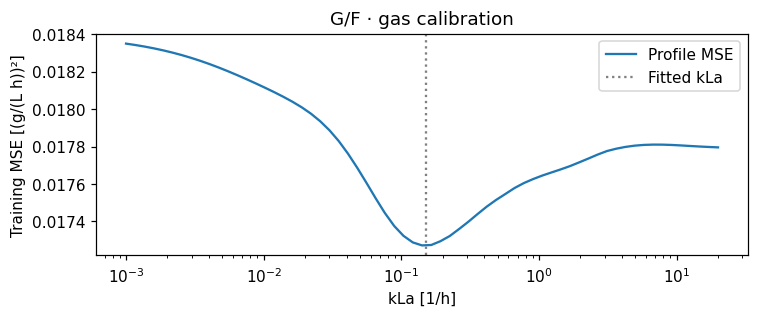

,LAB,role,RMSE,mass_error_g,half_step_max_error,Csat_min,Csat_max,produced_g,emitted_g,removed_g,final_dissolved_g
0,LAB019,Calibration,0.112240,7.938095e-15,3.156998e-06,1.481959,1.836705,121.609536,118.694314,0.365925,2.549296
1,LAB020,Calibration,0.074421,-1.554312e-15,4.303273e-07,1.613971,1.729750,118.751369,115.648724,0.332260,2.770385
2,LAB021,Calibration,0.183502,3.719247e-15,7.793893e-07,1.448400,1.625336,125.539605,122.439798,0.359465,2.740343
3,LAB016,Holdout,0.135665,0.000000e+00,2.788553e-07,1.504917,1.575170,146.495572,143.373809,0.000000,3.121763
4,LAB017,Holdout,0.134385,2.842171e-14,4.247397e-07,1.508751,1.572785,145.100865,141.976692,0.000000,3.124172
5,LAB018,Holdout,0.122654,0.000000e+00,4.124214e-07,1.504580,1.576138,146.502755,143.380183,0.000000,3.122572


,LAB,rol,n,RMSE,sesgo
0,LAB019,Calibración gas,166,0.112240,0.012932
1,LAB020,Calibración gas,172,0.074421,0.031482
2,LAB021,Calibración gas,166,0.183502,0.017241
3,LAB016,Holdout gas,152,0.135665,0.000533
4,LAB017,Holdout gas,141,0.134385,-0.037669
5,LAB018,Holdout gas,141,0.122654,-0.012401


,RMSE,sesgo
rol,,
Calibración gas,0.123388,0.020552
Holdout gas,0.130901,-0.016512


,LAB,inicio_5g_h,completa_10g_h
0,LAB019,11.9,19.9
1,LAB020,20.6,32.2
2,LAB021,10.9,17.7
3,LAB016,7.7,13.3
4,LAB017,7.9,13.5
5,LAB018,7.7,13.3


In [5]:
v=load(ROOT);LABS=['LAB019','LAB020','LAB021','LAB016','LAB017','LAB018'];TRAIN=LABS[:3];HOLD=LABS[3:]
raw=pd.read_csv(ROOT/'data/processed/co2_mass_balance_lab016_021_g_l_h.csv',usecols=['lab','time_h','record_kind','remaining_volume_L','co2_raw_g_l_h']);obs=observations(raw)
batches={};cores={};volumes={};caches={};activation={};entry=[]
for lab in LABS:
 b=v.batches[lab];ev=raw.loc[raw.lab.eq(lab)&raw.record_kind.eq('withdrawal_after')].sort_values('time_h');et=ev.time_h.to_numpy();vv=ev.remaining_volume_L.to_numpy()
 def volume(t,et=et,vv=vv):return np.r_[2.,vv][np.searchsorted(et,np.asarray(t),side='right')]
 volumes[lab]=volume
 if lab in TRAIN:b=replace(b,pulses={**b.pulses,'N':tuple((t,d*2/float(volume(t))) for t,d in b.pulses['N'])})
 if lab=='LAB017':b=replace(b,pulses={**b.pulses,'N':((min(t for t,d in b.pulses['N']),sum(d for t,d in b.pulses['N'])),)})
 if lab=='LAB021':b=replace(b,initials={**b.initials,'X':9.*.03})
 batches[lab]=b;f=simulate(b,theta);cores[lab]=f;f=with_jumps(f)
 tt=np.unique(np.r_[np.arange(0,float(f.index[-1]),.1),f.index[-1]])
 rates=[]
 for t in tt:
  y=[np.interp(t,f.index,f[s]) for s in kin.STATE_NAMES];q=kin.kinetic_terms(theta,kin.temperature_at(b,t),*y)
  if y[2]<=0 or y[3]<=0:q['mu']=0.
  rates.append((q['mu']/12.72+(q['beta_g']+q['beta_f'])/1.05)*y[0])
 caches[lab]=(tt,np.asarray(rates))
 consumed=b.initials['G']+b.initials['F']-np.interp(tt,f.index,f.GF)
 z=np.clip((consumed-5.)/5.,0.,1.);activation[lab]=z*z*(3.-2.*z)
 assert np.all(activation[lab][consumed<=5.]==0) and np.all(activation[lab][consumed>=10.]==1)
 entry.append(dict(LAB=lab,**b.initials,pulsos=b.pulses['N'],corte_h=v.horizons[lab]))
 obs[lab]=obs[lab].loc[obs[lab].time_h.between(0,v.horizons[lab])].copy()
display(pd.DataFrame(entry))

PCO2_BAR=1.0
ETHANOL_G_L_PER_VOL_PERCENT=7.8924
GAS_BOUNDS={'kLa':(0.001,20.),'gain':(.05,3.)}
GAS_INITIAL=(0.07467887635557982,0.635238911849421)
gas_fits={}

def saturation(T,E,S):
 a=np.maximum(E,0)/ETHANOL_G_L_PER_VOL_PERCENT
 return 3.295*np.exp((7e-5*a-.02905)*np.asarray(T)-.0179*a-.00111*np.maximum(S,0))*PCO2_BAR

def configure_gas(frames,single=False):
 global gas_equilibrium
 gas_equilibrium={}
 for lab,f in frames.items():
  times=caches[lab][0]
  ff=plotframe_s(f) if single else with_jumps(f)
  T=np.array([kin.temperature_at(batches[lab],float(t)) for t in times])
  E=np.interp(times,ff.index,ff.E)
  S=np.interp(times,ff.index,ff.S if single else ff.GF)
  gas_equilibrium[lab]=(T,E,S,saturation(T,E,S))

def gas(lab,k,gain=1,activated=True,substeps=1):
 t,source=caches[lab]
 source=source*activation[lab] if activated else source.copy()
 T,E,S,sat=gas_equilibrium[lab]
 cd=np.zeros(len(t));qout=np.zeros(len(t));acc=np.zeros(len(t))
 qout[0]=max(source[0]-k*sat[0],0.)
 for i,dt in enumerate(np.diff(t),1):
  qp=(source[i-1]+source[i])/2;previous=cd[i-1];current=previous
  for j in range(substeps):
   h=dt/substeps;fraction=(j+.5)/substeps;cs=sat[i-1]*(1-fraction)+sat[i]*fraction
   if current>cs:
    current=cs+(current-cs)*np.exp(-k*h)
   else:
    D=cs-current
    if qp<=0 or D<=0:delta=0.
    elif k*D<=qp:delta=D*(-np.expm1(-k*h))
    else:
     crossing=(D-qp/k)/qp;linear=min(h,crossing);delta=qp*linear
     if crossing<h:delta+=(qp/k)*(-np.expm1(-k*(h-crossing)))
    current+=delta
  cd[i]=current;acc[i]=(current-previous)/dt;qout[i]=qp-acc[i]
 assert cd.min()>=-1e-12 and qout.min()>-1e-10
 assert np.max(abs(np.diff(cd)-np.diff(t)*((source[:-1]+source[1:])/2-qout[1:])))<1e-10
 return pd.DataFrame(dict(qprod=source,Cd=cd,Csat=sat,T=T,E=E,S=S,qgas=qout,qpred=gain*qout),index=t)

def calibrate_gas(model):
 # Analytic gain eliminates a redundant numerical search direction.
 def evaluate(logk,details=False):
  k=float(np.exp(logk));xy=xx=0.;pairs=[]
  for lab in TRAIN:
   f=gas(lab,k);o=obs[lab];x=np.interp(o.time_h,f.index,f.qgas);y=o.co2_raw_g_l_h.to_numpy()
   xx+=float(np.mean(x*x));xy+=float(np.mean(x*y));pairs.append((x,y))
  g=float(np.clip(xy/xx,*GAS_BOUNDS['gain']))
  objective=float(np.mean([np.mean((g*x-y)**2) for x,y in pairs]))
  return (objective,k,g) if details else objective
 grid=np.unique(np.r_[np.linspace(*np.log(GAS_BOUNDS['kLa']),65),np.log(GAS_INITIAL[0])])
 values=np.array([evaluate(x) for x in grid]);candidates=[evaluate(grid[0],True),evaluate(grid[-1],True)]
 for i in range(1,len(grid)-1):
  if values[i]<=values[i-1] and values[i]<=values[i+1]:
   result=minimize_scalar(evaluate,bounds=(grid[i-1],grid[i+1]),method='bounded',options={'xatol':1e-7})
   assert result.success
   candidates.append(evaluate(result.x,True))
 objective,k,g=min(candidates)
 profile=pd.DataFrame([dict(kLa=np.exp(x),gain=evaluate(x,True)[2],MSE=y) for x,y in zip(grid,values)])
 record=dict(model=model,kLa=k,gain=g,training_MSE=objective,training=TRAIN,holdout=HOLD,
             kLa_at_bound=bool(np.isclose(k,GAS_BOUNDS['kLa'][0]) or np.isclose(k,GAS_BOUNDS['kLa'][1])),
             gain_at_bound=bool(np.isclose(g,GAS_BOUNDS['gain'][0]) or np.isclose(g,GAS_BOUNDS['gain'][1])))
 gas_fits[model]=record
 print('GAS_FIT_JSON',json.dumps(record));display(profile)
 fig,ax=plt.subplots(figsize=(7,3));ax.semilogx(profile.kLa,profile.MSE,label='Profile MSE');ax.axvline(k,c='gray',ls=':',label='Fitted kLa')
 ax.set(xlabel='kLa [1/h]',ylabel='Training MSE [(g/(L h))²]',title=model+' · gas calibration');ax.legend(loc='best');fig.tight_layout();plt.show()
 checks=[]
 for lab in LABS:
  f=gas(lab,k,g);fine=gas(lab,k,g,substeps=2);tt=f.index.to_numpy();dt=np.diff(tt);V=volumes[lab](tt);cd=f.Cd.to_numpy();src=f.qprod.to_numpy()
  produced=np.sum(V[:-1]*dt*(src[:-1]+src[1:])/2);emitted=np.sum(V[:-1]*dt*f.qgas.to_numpy()[1:]);removed=np.sum((V[:-1]-V[1:])*cd[1:])
  error=V[-1]*cd[-1]-V[0]*cd[0]-produced+emitted+removed
  assert abs(error)<1e-8
  o=obs[lab];err=np.interp(o.time_h,f.index,f.qpred)-o.co2_raw_g_l_h.to_numpy()
  coarse_obs=np.interp(o.time_h,f.index,f.qpred);fine_obs=np.interp(o.time_h,fine.index,fine.qpred)
  step_error=float(np.max(abs(coarse_obs-fine_obs)))
  assert step_error<.005,('Time-step sensitivity',lab,step_error)
  checks.append(dict(LAB=lab,role='Calibration' if lab in TRAIN else 'Holdout',RMSE=float(np.sqrt(np.mean(err**2))),mass_error_g=float(error),half_step_max_error=step_error,Csat_min=float(f.Csat.min()),Csat_max=float(f.Csat.max()),produced_g=float(produced),emitted_g=float(emitted),removed_g=float(removed),final_dissolved_g=float(V[-1]*cd[-1])))
 display(pd.DataFrame(checks));print('GAS_CHECKS_JSON',json.dumps(checks))
 return k,g

configure_gas(cores)
KLA,GAIN=calibrate_gas('G/F')

curves={lab:gas(lab,KLA,GAIN) for lab in LABS};metrics=[]
for lab in LABS:
 o=obs[lab];f=curves[lab];e=np.interp(o.time_h,f.index,f.qpred)-o.co2_raw_g_l_h
 metrics.append(dict(LAB=lab,rol='Calibración gas' if lab in TRAIN else 'Holdout gas',n=len(o),RMSE=np.sqrt(np.mean(e*e)),sesgo=np.mean(e)))
metrics=pd.DataFrame(metrics);display(metrics);display(metrics.groupby('rol')[['RMSE','sesgo']].mean())

display(pd.DataFrame([dict(LAB=lab,inicio_5g_h=float(caches[lab][0][np.flatnonzero(activation[lab]>0)[0]]),completa_10g_h=float(caches[lab][0][np.flatnonzero(activation[lab]>=1)[0]])) for lab in LABS]))


## Holdout LAB022–024

Predicción del modelo G/F con los parámetros químicos del notebook y los parámetros de gas ya guardados en su versión ejecutada. La simulación abarca hasta las 190 h. Las condiciones iniciales siguen las del notebook 13. La química de inoculación y la primera muestra de biomasa a las 0,25 h inicializan la simulación. Para el etanol inicial se usan 10,010194 g/L. La temperatura proviene del respaldo del ensayo.

En la hora registrada de nutrición se aplica un pulso de 1 g de SFX y 0,4 g de FDA por lote. Con el volumen remanente y la conversión del notebook 13, el aporte nominal es 99,9 mg N/L. Las muestras posteriores se usan para evaluar las predicciones en sus horas de toma. El flujo se compara en ventanas de 30 minutos con observaciones reales válidas. Las curvas de etanol y CO₂ disuelto muestran las predicciones disponibles para esas variables.

La integración localiza el agotamiento que activa la condición de crecimiento de cada modelo y continúa desde ese punto.

La última fila de las figuras corresponde a LAB022–024. Sus paneles de flujo muestran promedios de 30 minutos. Las filas previas usan el soporte de medición de sus ensayos.

In [6]:
HOLDOUT_MODEL = 'G/F'
HOLDOUT_SINGLE = False
HOLDOUT_GAS_PARAMS = (0.15007991020720535, 0.6460643588058115)

import nbformat
from types import FunctionType

instrument = json.loads((ROOT / "configs/co2_instrument.json").read_text(encoding="utf-8"))
prep_path = ROOT / "notebooks/preparing_data/lab022_024_data.source.ipynb"
prep_nb = nbformat.read(prep_path, as_version=4)
sample_code = [cell.source for cell in prep_nb.cells if cell.cell_type == "code" and
               any(marker in cell.source for marker in
                   ("workbook = data_dir /", "y15_sources = {", "oculyze_frames = []"))]
assert len(sample_code) == 3
prepared = {}
for source in sample_code:
    python_source = "\n".join(line for line in source.splitlines() if not line.startswith("%"))
    exec(compile(python_source, str(prep_path), "exec"), prepared)

holdout_labs = prepared["labs"]
holdout_biomass = prepared["oculyze"].assign(X_g_L=lambda f: .03 * f["Viable concentration"])
holdout_chemistry = prepared["chemistry"]
holdout_nutrition = (prepared["nutrition"] - prepared["inoculation"]).dt.total_seconds() / 3600
holdout_horizon = 190.
# Dosis confirmada por lote. Equivalente de YAN de SFX y fracción de N en FDA.
pulse_mass_n_g = 1.0 * .10 + .4 * (2 * 14.007 / 132.1)

reactors = prepared["experiments"]["Fermentador"]
reactor_map = pd.Series(reactors.index, index=reactors)
def read_holdout_backup(filename, value):
    frame = pd.read_csv(prepared["data_dir"] / filename,
                        usecols=["timestamp", "fermentador", value], parse_dates=["timestamp"])
    frame["lab"] = frame["fermentador"].map(reactor_map)
    frame["h"] = (frame["timestamp"] - frame["lab"].map(prepared["inoculation"])).dt.total_seconds() / 3600
    return frame.loc[frame["h"].ge(0)].sort_values("h")

holdout_temperature = read_holdout_backup("backup_global_temperatura.csv", "T")
holdout_raw_flow = read_holdout_backup("backup_global_co2.csv", "flow_sccm")
mass_factor = 44.0095 * 60 * instrument["co2_correction_factor"] / (1000 * 24.16)
holdout_batches, holdout_flow, pulse_rows = {}, {}, []
for lab in holdout_labs:
    samples = prepared["offline"].loc[prepared["offline"]["lab"].eq(lab)]
    withdrawals = samples.loc[samples["Observaciones"].eq("se quitan 50ml"), "hours"].to_numpy()
    initial_volume = float(prepared["experiments"].at[lab, "Volumen_Inicial_L"].removesuffix("L"))
    pulse_h = holdout_nutrition[lab]
    pulse_volume = initial_volume - .05 * np.searchsorted(withdrawals, pulse_h, side="right")
    pulse_n = pulse_mass_n_g / pulse_volume
    start_sample = holdout_biomass.loc[holdout_biomass["lab"].eq(lab) &
                                       holdout_biomass["sample"].eq("01")].iloc[0]
    start = float(start_sample["hours"])
    assert start == .25
    chem = holdout_chemistry.loc[holdout_chemistry["lab"].eq(lab)]
    initial = chem.loc[chem["sample"].eq("01")].iloc[0]
    initials = {"X": start_sample["X_g_L"], "N": initial["YAN for plot"] / 1000,
                "G": initial["GLUCOSE-320"], "F": initial["Fructose (derived)"], "E": 10.010194}
    biomass_h = holdout_biomass.loc[holdout_biomass["lab"].eq(lab), "hours"]
    # Se incluyen las horas de muestreo para evaluar la solución directamente.
    times = np.unique(np.r_[np.arange(start, holdout_horizon, .1), holdout_horizon, pulse_h,
                           chem.loc[chem["hours"].ge(start), "hours"], biomass_h])
    temp = holdout_temperature.loc[holdout_temperature["lab"].eq(lab)].copy()
    assert temp["h"].min() <= start and temp["h"].max() >= holdout_horizon
    temp["minute"] = np.floor(temp["h"] * 60 + 1e-10).astype(int)
    median_temp = temp.groupby("minute")["T"].median()
    temp_c = np.interp(times, (median_temp.index.to_numpy() + 1) / 60, median_temp)
    holdout_batches[lab] = kin.BatchData(
        medium="natural", batch=lab, time=times, temperature_c=temp_c,
        pulses={"N": ((pulse_h, pulse_n),)}, observations={}, initials=initials,
    )
    pulse_rows.append({"LAB": lab, "Pulso [h]": pulse_h, "Volumen [L]": pulse_volume,
                       "Aporte [mg N/L]": 1000 * pulse_n})
    raw = holdout_raw_flow.loc[holdout_raw_flow["lab"].eq(lab) &
                               holdout_raw_flow["h"].gt(0)].copy()
    assert raw["h"].max() >= holdout_horizon
    raw["bin"] = np.ceil(raw["h"] / .5 - 1e-10).astype(int)
    volumes = initial_volume - .05 * np.searchsorted(withdrawals, raw["h"], side="right")
    raw["mass_flow"] = raw["flow_sccm"] * mass_factor / volumes
    means = {}
    for index, window in raw.groupby("bin"):
        end = index * .5
        if end > holdout_horizon:
            break
        gaps = np.diff(np.r_[end - .5, window["h"], end])
        valid = len(window) >= 30 and gaps.max() <= 2 / 60 + 1e-10
        means[end] = window["mass_flow"].mean() if valid else np.nan
    holdout_flow[lab] = pd.Series(means).reindex(np.arange(.5, holdout_horizon + .5, .5))
display(pd.DataFrame(pulse_rows).set_index("LAB").round(3))

,Pulso [h],Volumen [L],Aporte [mg N/L]
LAB,,,
LAB022,113.633,1.85,99.906
LAB023,113.783,1.85,99.906
LAB024,113.883,1.85,99.906


In [7]:
def simulate_holdout(batch):
    # Se localiza el agotamiento antes de aplicar la ecuación sin crecimiento.
    sugar_indices = (2,) if HOLDOUT_SINGLE else (2, 3)
    def integrate_to_event(rhs, interval, initial, *, t_eval, **options):
        depleted = [index for index in sugar_indices if initial[index] <= 0]

        def after_depletion(t, state, index):
            state = state.copy()
            state[index] = 0.
            derivative = rhs(t, state)
            derivative[index] = 0.
            return derivative

        if len(depleted):
            return solve_ivp(lambda t, y: after_depletion(t, y, depleted[0]),
                             interval, initial, t_eval=t_eval, **options)

        def depletion_event(index):
            def event(t, state):
                return state[index]
            event.terminal = True
            event.direction = -1
            return event

        def before_depletion(t, state):
            # Las etapas de prueba pueden cruzar cero antes de que el solver localice el evento.
            state = state.copy()
            state[list(sugar_indices)] = np.maximum(state[list(sugar_indices)], np.finfo(float).tiny)
            return rhs(t, state)

        before = solve_ivp(before_depletion, interval, initial, t_eval=t_eval,
                           events=[depletion_event(index) for index in sugar_indices], **options)
        if before.status != 1:
            return before
        [event_index] = [i for i, hits in enumerate(before.t_events) if len(hits)]
        event_time = before.t_events[event_index][0]
        state = before.y_events[event_index][0].copy()
        index = sugar_indices[event_index]
        state[index] = 0.
        remaining = t_eval[t_eval > event_time]
        if not len(remaining):
            return before
        after = solve_ivp(lambda t, y: after_depletion(t, y, index),
                          (event_time, interval[1]), state, t_eval=remaining, **options)
        after.t = np.r_[before.t, after.t]
        before_states = np.asarray(before.y).reshape(len(initial), -1)
        after.y = np.column_stack([before_states, after.y])
        return after

    simulate_context = dict(globals(), solve_ivp=integrate_to_event)
    model_simulate, parameters = (simulate_s, ps) if HOLDOUT_SINGLE else (simulate, theta)
    return FunctionType(model_simulate.__code__, simulate_context)(batch, parameters)

holdout_kinetic, holdout_plot, holdout_source, holdout_activation = {}, {}, {}, {}
for lab, batch in holdout_batches.items():
    trajectory = simulate_holdout(batch)
    frame = plotframe_s(trajectory) if HOLDOUT_SINGLE else with_jumps(trajectory)
    holdout_kinetic[lab], holdout_plot[lab] = trajectory, frame
    if HOLDOUT_SINGLE:
        [(pulse_h, before, after)] = trajectory.attrs["jumps"]
    else:
        [jump] = trajectory.attrs["pulse_jumps"]
        pulse_h, before, after = jump["t"], jump["before"], jump["after"]
    np.testing.assert_allclose([pulse_h, after[1] - before[1]], batch.pulses["N"][0], atol=1e-12)
    times = np.r_[np.arange(batch.time[0], holdout_horizon, .1), holdout_horizon]
    source = []
    variables = ["X", "N", "S", "E"] if HOLDOUT_SINGLE else kin.STATE_NAMES
    for t in times:
        y = [np.interp(t, frame.index, frame[state]) for state in variables]
        if HOLDOUT_SINGLE:
            mu, fermentation, _, _ = terms_s(t, y, ps, batch)
        else:
            rates = kin.kinetic_terms(theta, kin.temperature_at(batch, t), *y)
            mu = rates["mu"] if y[2] > 0 and y[3] > 0 else 0.
            fermentation = rates["beta_g"] + rates["beta_f"]
        source.append((mu / 12.72 + fermentation / 1.05) * y[0])
    sugar = frame["S" if HOLDOUT_SINGLE else "GF"]
    consumed = sugar.iloc[0] - np.interp(times, frame.index, sugar)
    z = np.clip((consumed - 5.) / 5., 0., 1.)
    holdout_activation[lab] = z * z * (3. - 2. * z)
    holdout_source[lab] = (times, np.asarray(source))

# El integrador de gas usa diccionarios globales. Cada ejecución del holdout recibe los suyos.
gas_context = dict(globals(), batches=holdout_batches, caches=holdout_source, activation=holdout_activation)
FunctionType(configure_gas.__code__, gas_context)(holdout_kinetic, HOLDOUT_SINGLE)
predict_gas = FunctionType(gas.__code__, gas_context, argdefs=gas.__defaults__)
holdout_gas = {lab: predict_gas(lab, *HOLDOUT_GAS_PARAMS) for lab in holdout_labs}
holdout_mean_gas = {}
for lab, curve in holdout_gas.items():
    times = curve.index.to_numpy()
    cumulative = np.r_[0., np.cumsum(np.diff(times) * curve["qpred"].to_numpy()[1:])]
    ends = holdout_flow[lab].index.to_numpy()
    ends = ends[ends - .5 >= times[0]]
    mean = (np.interp(ends, times, cumulative) - np.interp(ends - .5, times, cumulative)) / .5
    holdout_mean_gas[lab] = pd.Series(mean, index=ends)

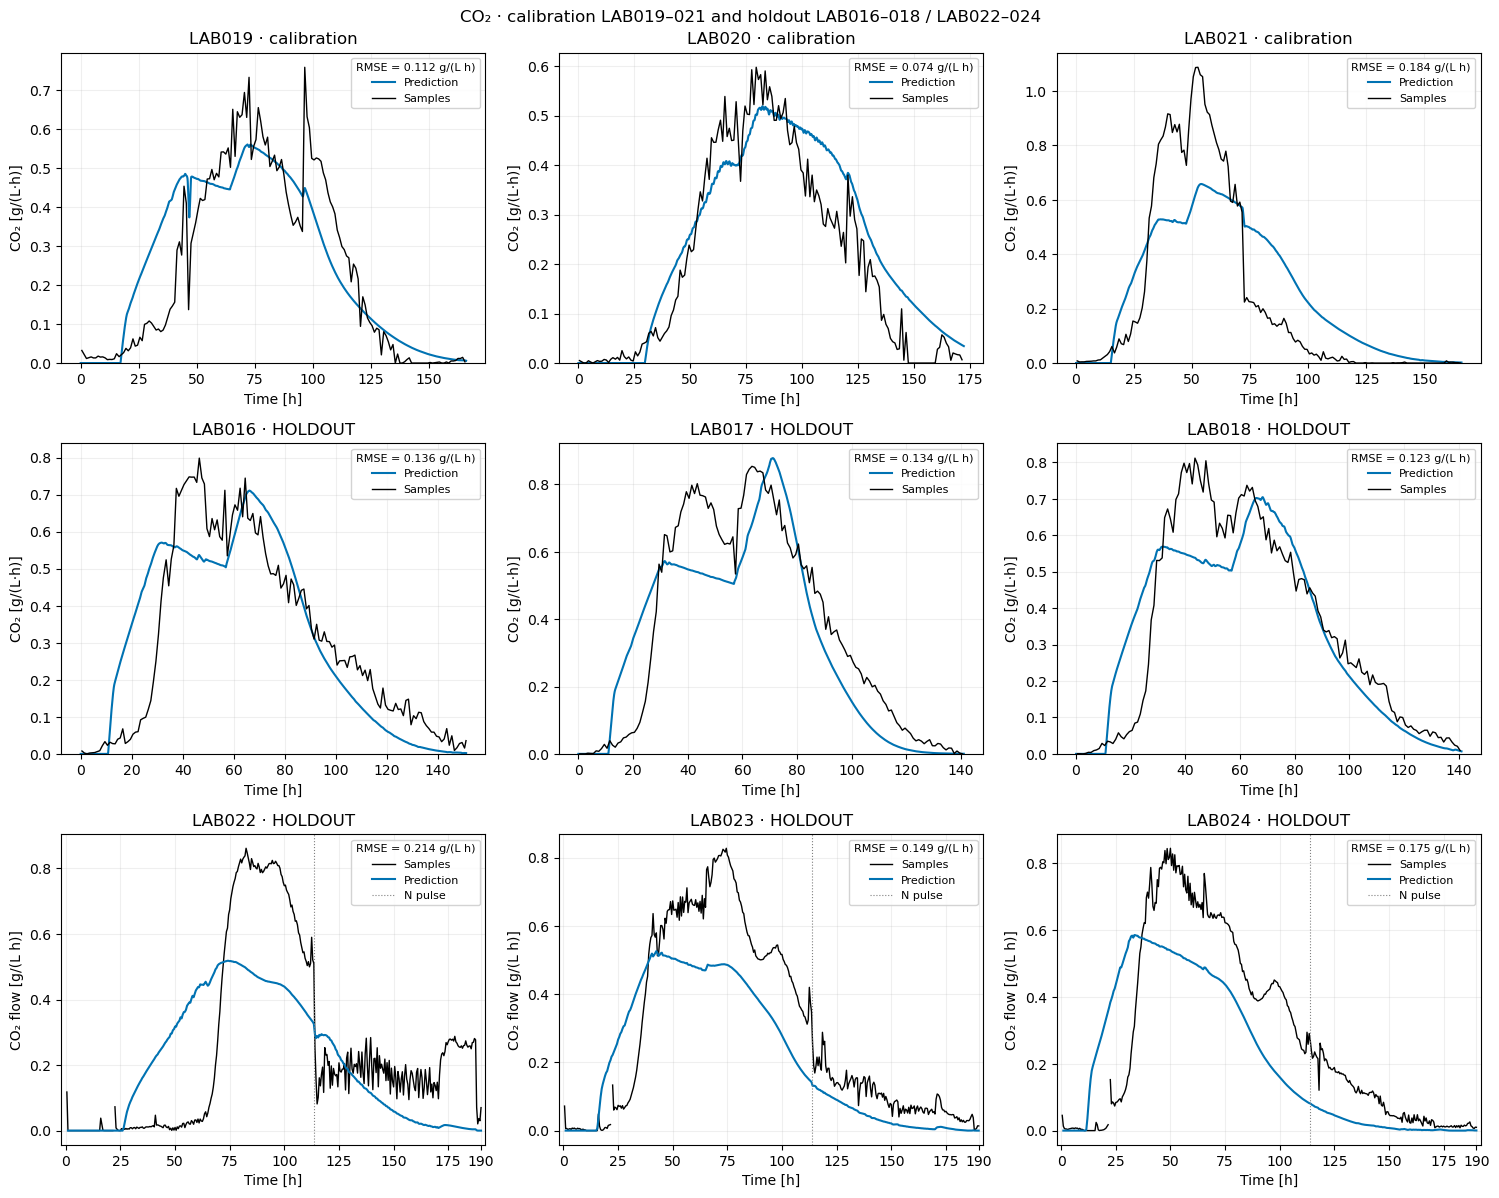

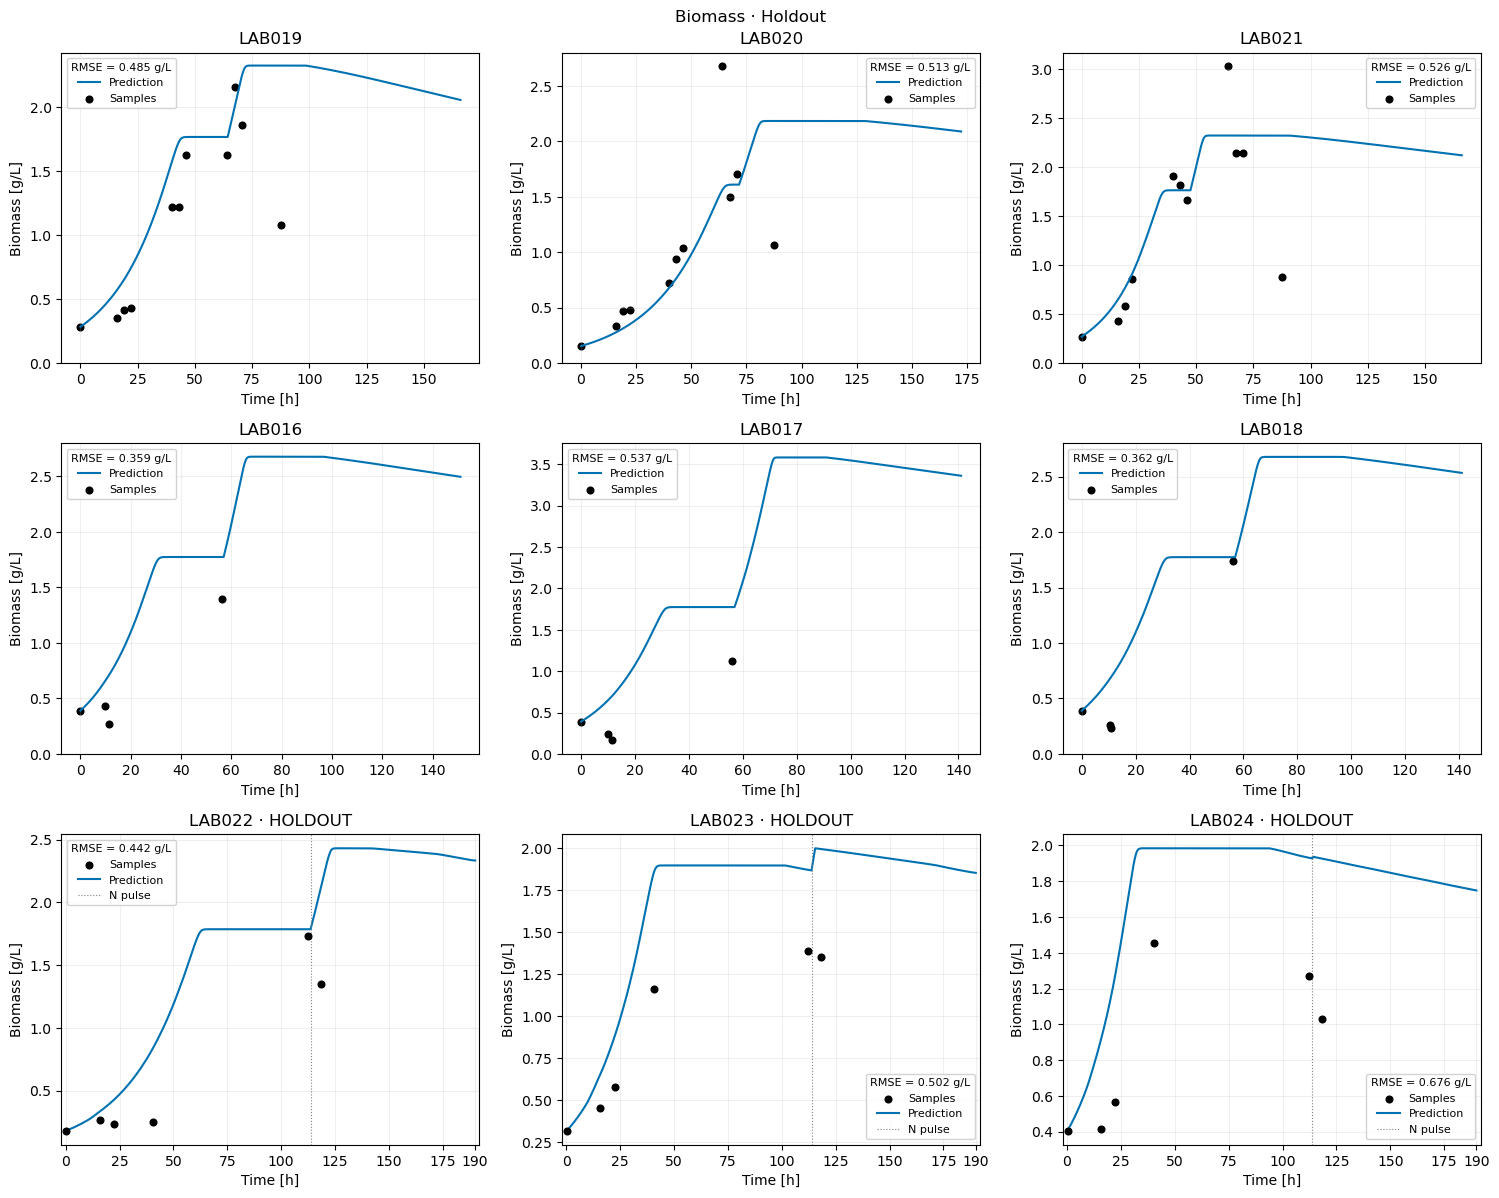

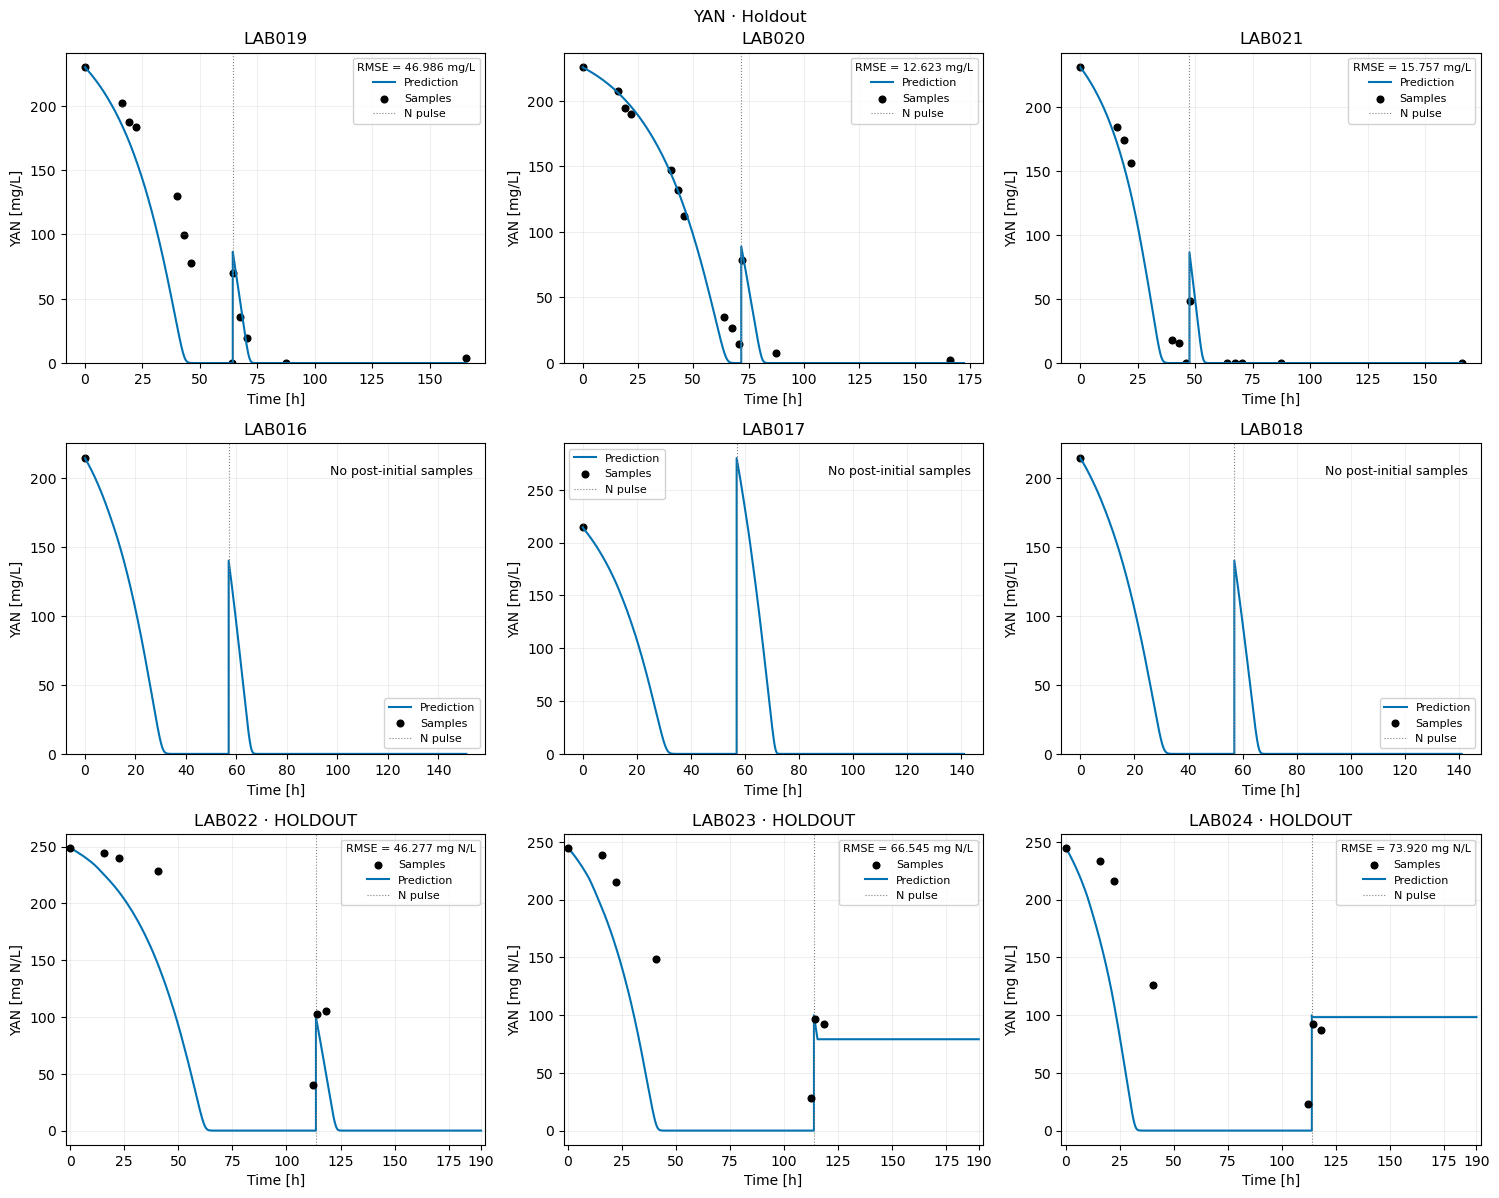

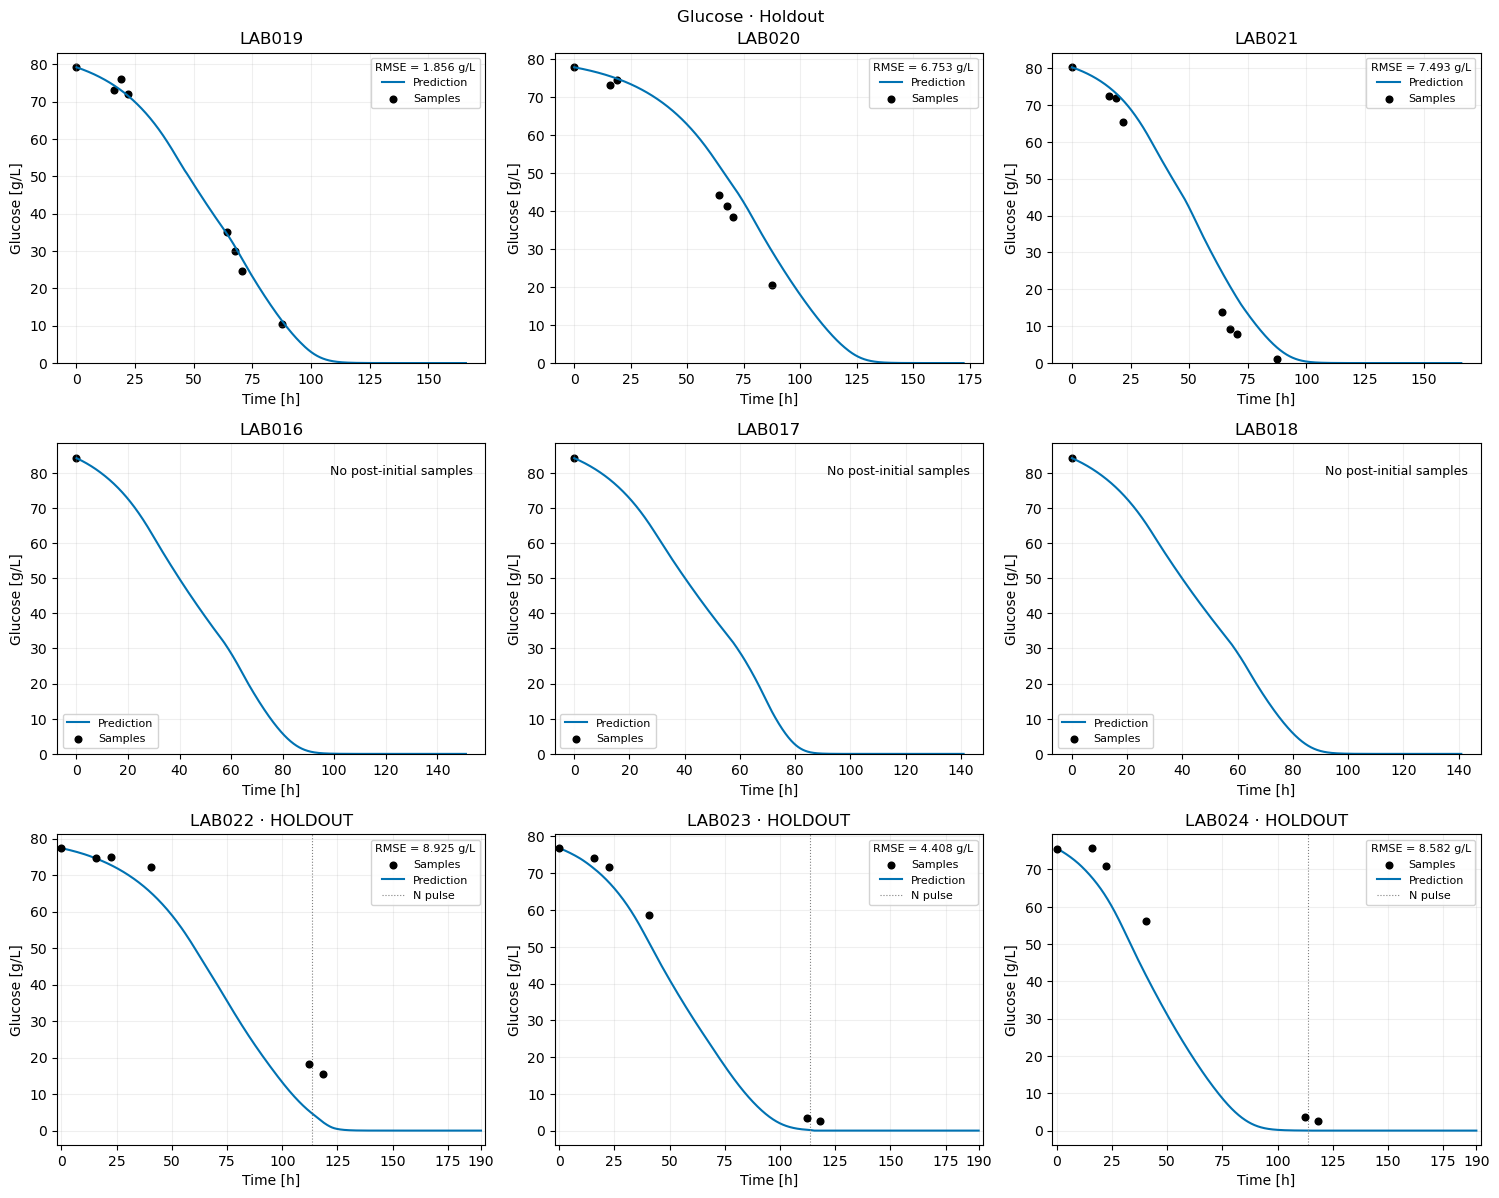

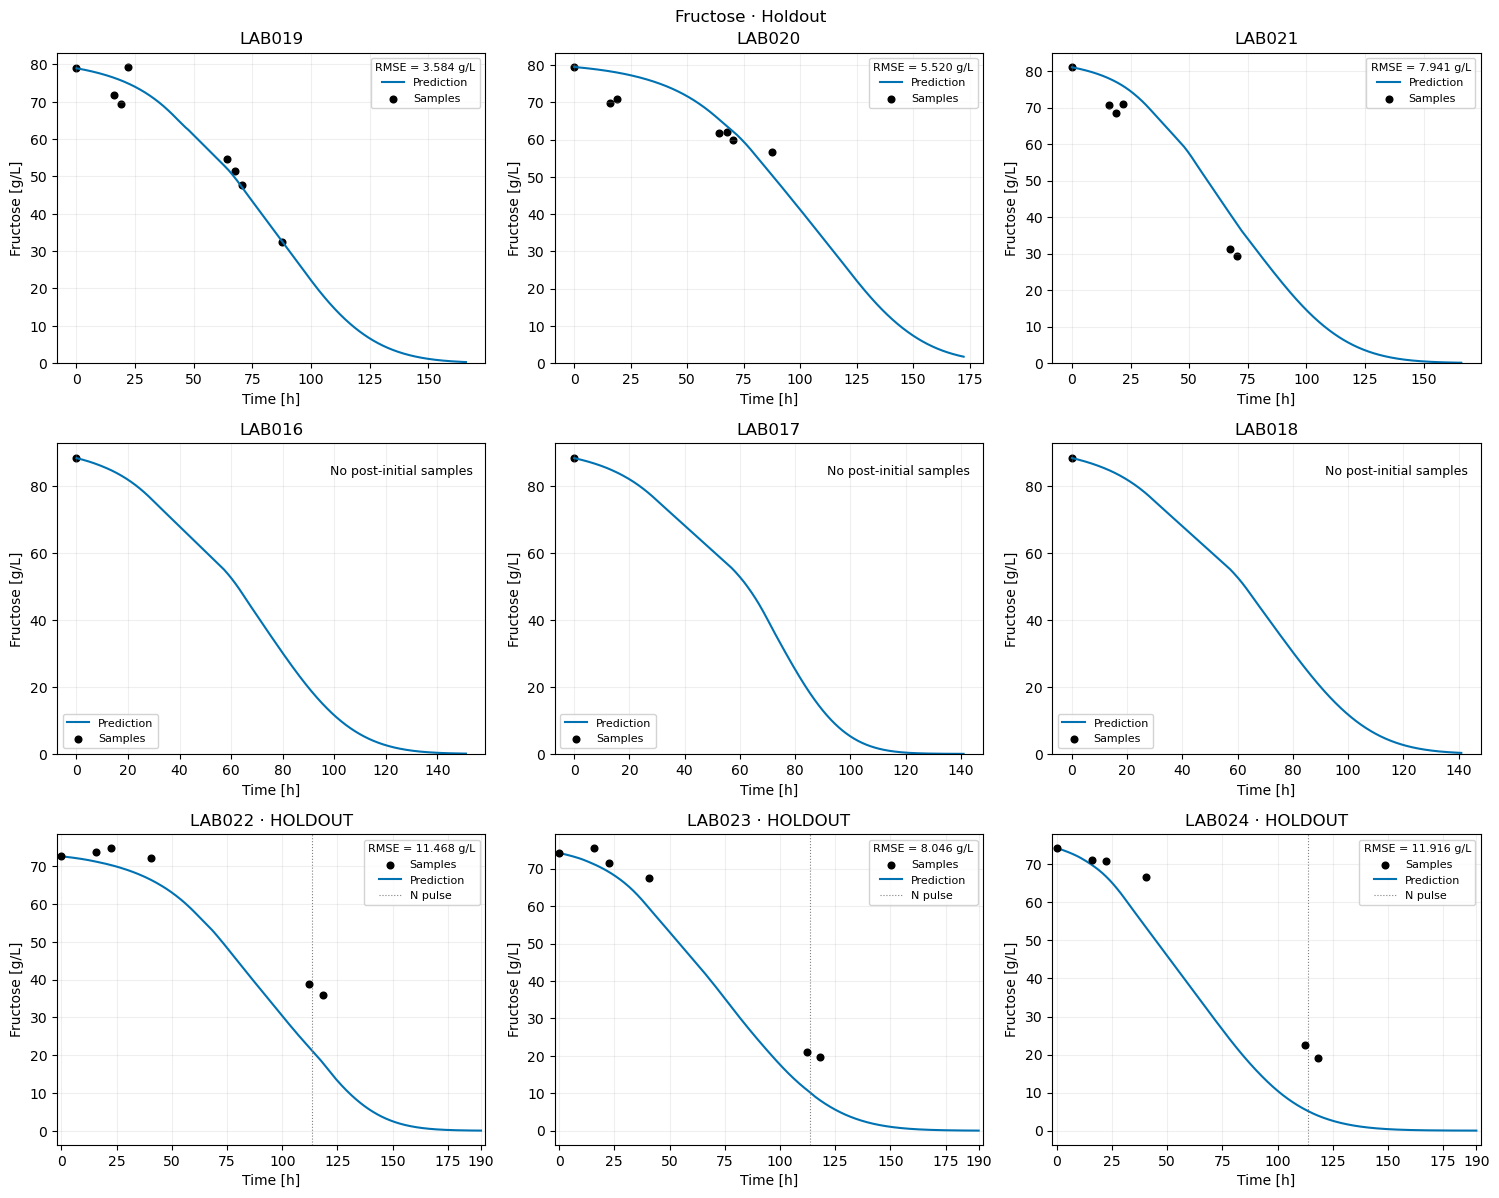

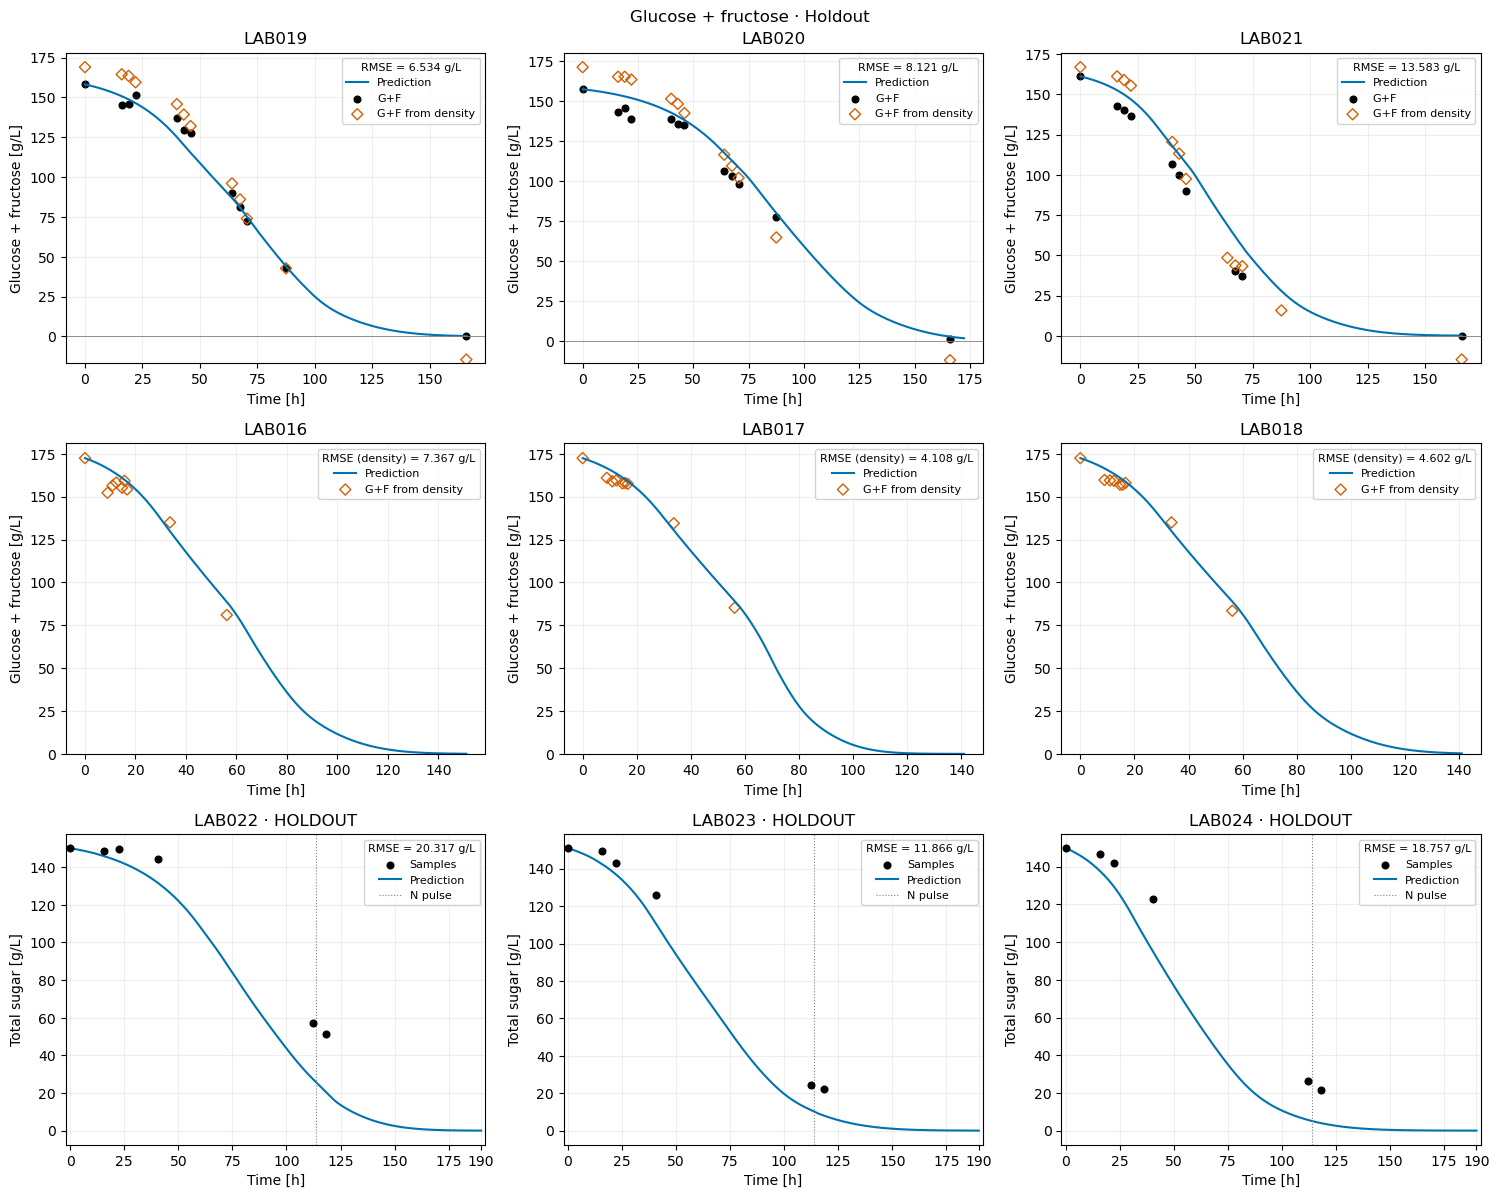

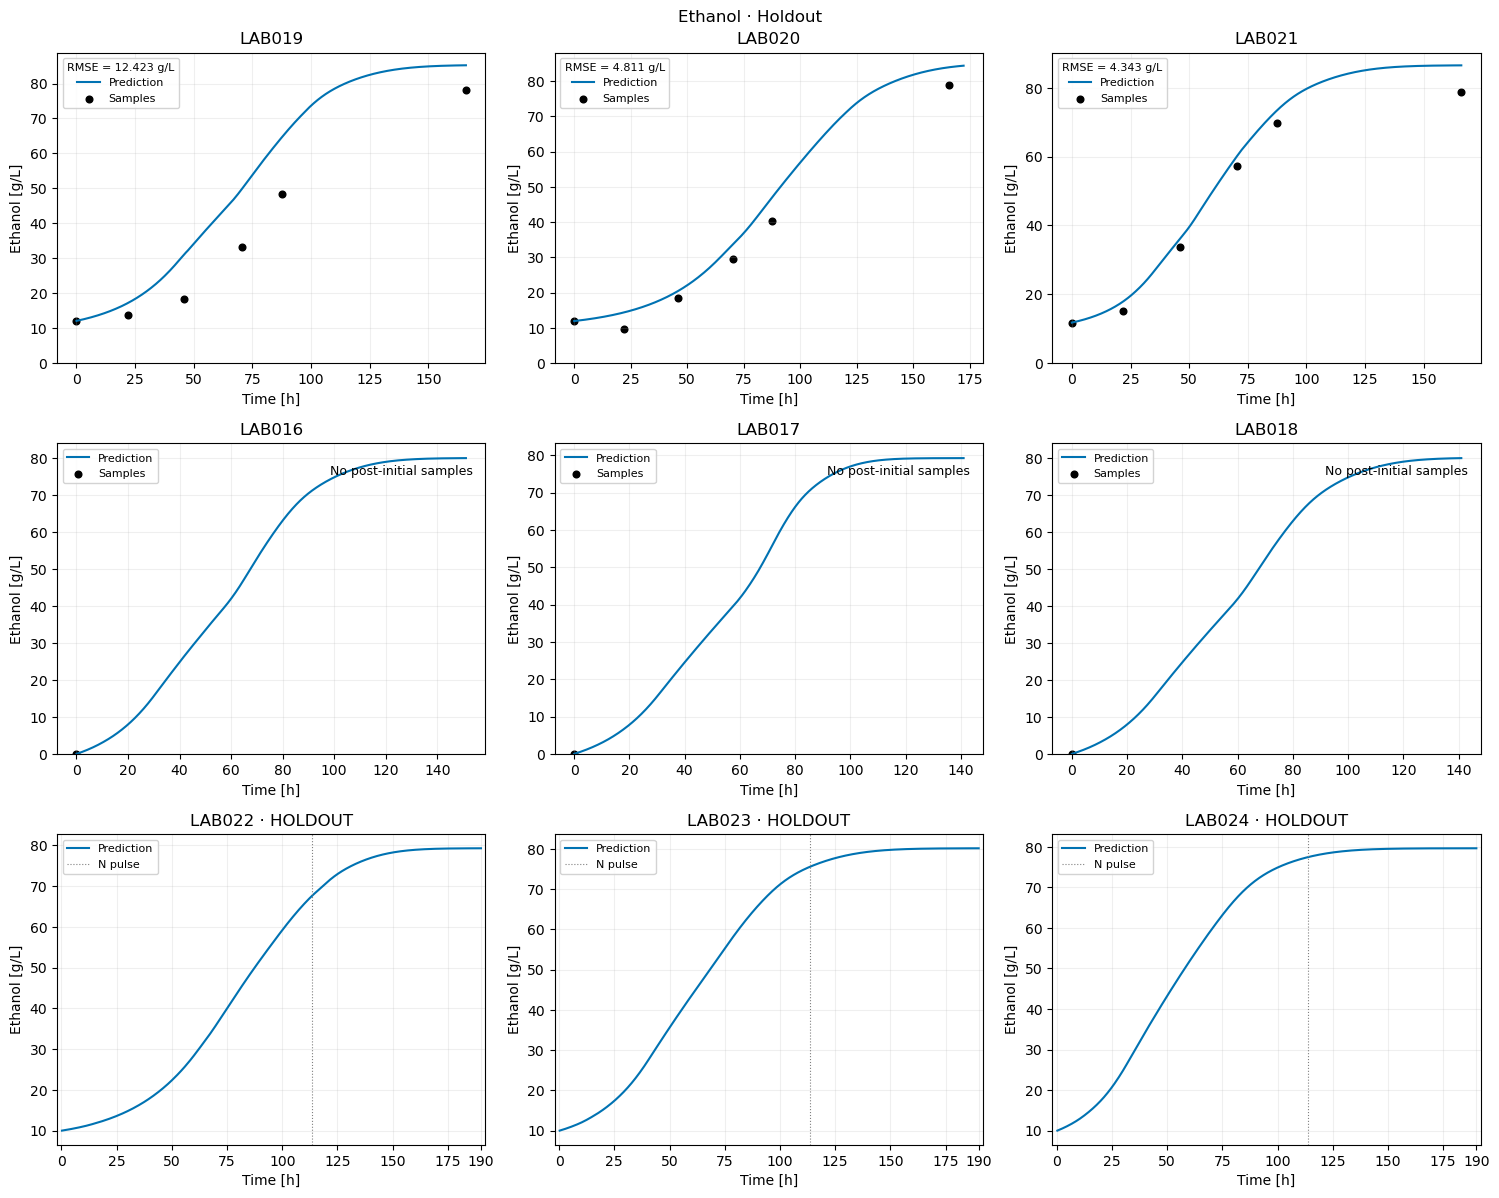

,LAB,variable,n,RMSE
0,LAB019,X,10,0.484605
1,LAB020,X,10,0.513404
2,LAB021,X,10,0.526470
3,LAB016,X,3,0.359155
4,LAB017,X,3,0.536581
5,LAB018,X,3,0.362133
6,LAB019,N,12,46.985655
7,LAB020,N,12,12.622841
8,LAB021,N,12,15.757195
9,LAB019,G,7,1.855855


,n_mediciones
lab,
LAB016,9
LAB017,9
LAB018,9
LAB019,12
LAB020,12
LAB021,12


G+F from density = 2.5*(densidad g/L - 1000); comparación gráfica, no usada en el ajuste; se conservan valores negativos de la conversión.


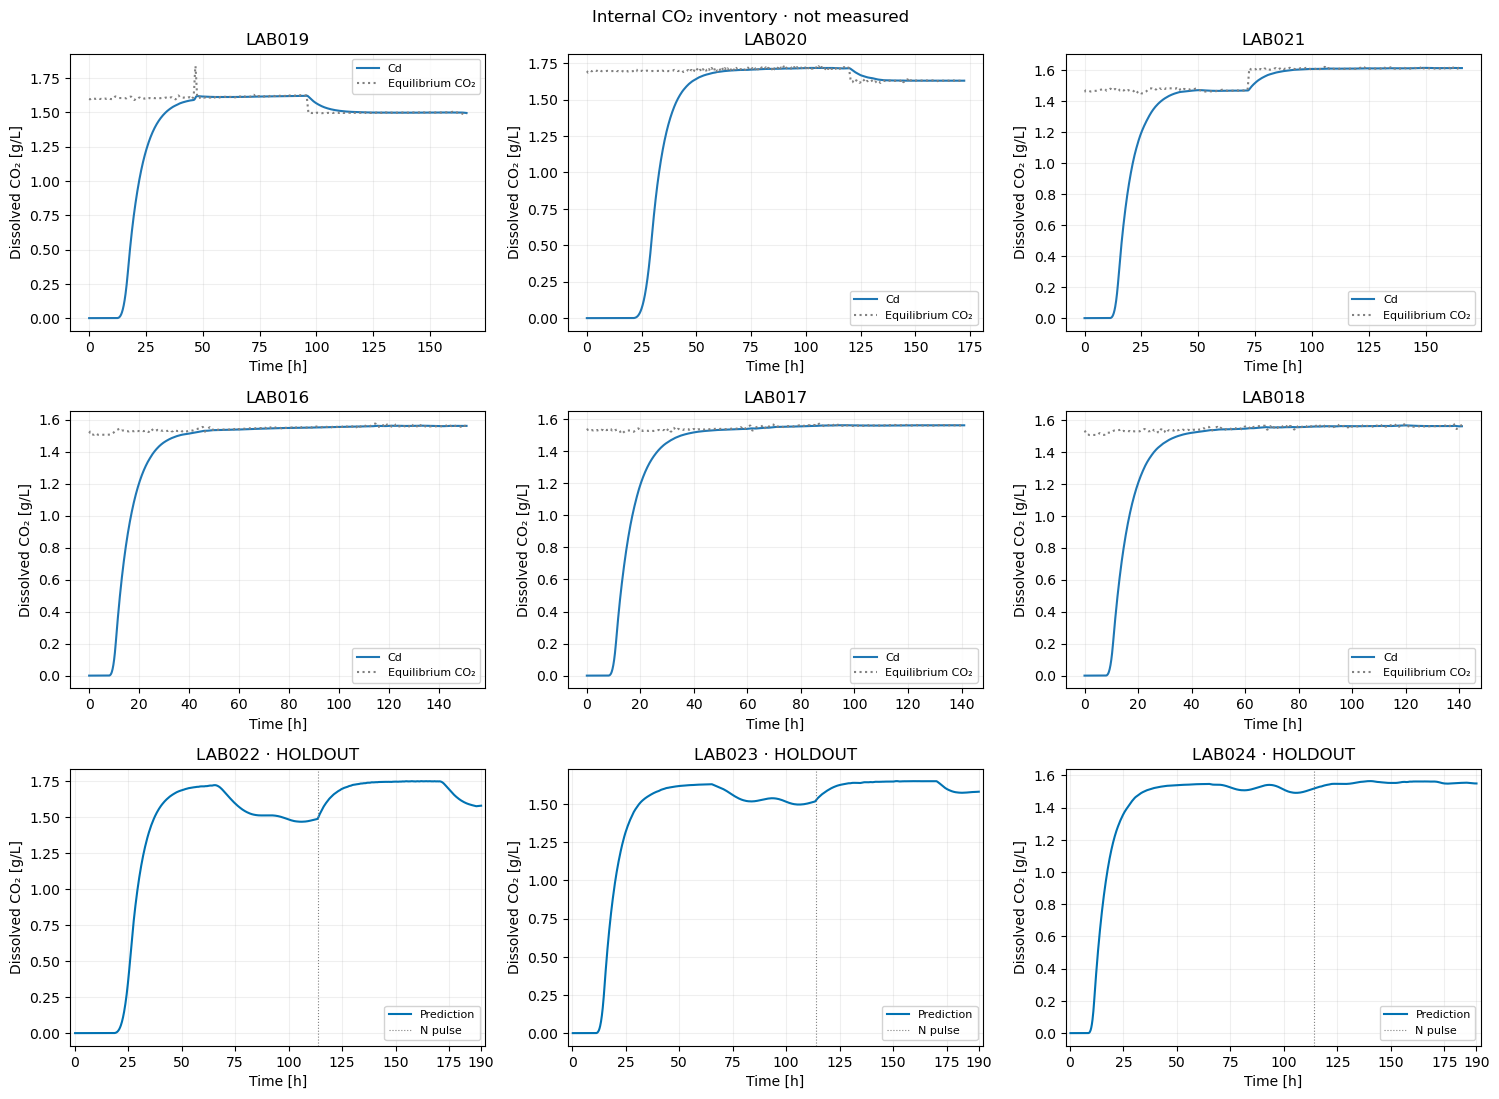

,LAB,LAB022,LAB023,LAB024
Variable,Unit,,,
Biomass,g/L,0.4422,0.5022,0.6755
CO₂ flow · 30-min mean,g/(L h),0.2139,0.1495,0.1753
Fructose,g/L,11.4678,8.0456,11.9163
Glucose,g/L,8.9247,4.4076,8.5823
Total sugar,g/L,20.3170,11.8664,18.7571
YAN,mg N/L,46.2775,66.5449,73.9200


In [8]:
panels = [
    ("X", "Biomass", "g/L", holdout_biomass, "X_g_L", 1.),
    ("N", "YAN", "mg N/L", holdout_chemistry, "YAN for plot", 1000.),
]
if not HOLDOUT_SINGLE:
    panels.extend([
        ("G", "Glucose", "g/L", holdout_chemistry, "GLUCOSE-320", 1.),
        ("F", "Fructose", "g/L", holdout_chemistry, "Fructose (derived)", 1.),
    ])
panels.extend([
    ("S" if HOLDOUT_SINGLE else "GF", "Total sugar", "g/L", holdout_chemistry, "GLU-FRU-320", 1.),
    ("E", "Ethanol", "g/L", None, None, 1.),
    ("Cd", "Dissolved CO₂", "g/L", None, None, 1.),
    ("CO2", "CO₂ flow · 30-min mean", "g/(L h)", None, None, 1.),
])
holdout_metrics = []
holdout_panels = {panel[0]: panel[1:] for panel in panels}


def draw_lab022_024_row(axes, state):
    title, unit, sample_frame, column, factor = holdout_panels[state]
    for ax, lab in zip(axes, holdout_labs):
        errors = np.array([])
        if state == "CO2":
            prediction = holdout_mean_gas[lab]
            observed = holdout_flow[lab]
            ax.plot(observed.index, observed, color="black", lw=1, label="Samples")
            errors = (prediction - observed).dropna().to_numpy()
        elif state == "Cd":
            prediction = holdout_gas[lab]["Cd"]
        else:
            prediction = holdout_plot[lab][state] * factor
            if sample_frame is not None:
                samples = sample_frame.loc[sample_frame["lab"].eq(lab)].dropna(subset=[column])
                ax.scatter(samples["hours"], samples[column], c="black", s=23, label="Samples", zorder=5)
                evaluation = samples.loc[samples["sample"].ne("01")]
                at_sample = holdout_kinetic[lab].loc[evaluation["hours"].to_numpy(), state].to_numpy()
                errors = at_sample * factor - evaluation[column].to_numpy()
        ax.plot(prediction.index, prediction, c="#0072B2", lw=1.5, label="S model" if HOLDOUT_SINGLE else "Prediction")
        ax.axvline(holdout_nutrition[lab], c="gray", ls=":", lw=.8, label="N pulse")
        legend_title = None
        if len(errors):
            rmse = np.sqrt(np.mean(errors**2))
            holdout_metrics.append({"LAB": lab, "Variable": title, "n": len(errors), "RMSE": rmse, "Unit": unit})
            legend_title = f"RMSE = {rmse:.3f} {unit}"
        ax.set(title=f"{lab} · HOLDOUT", xlabel="Time [h]", xlim=(-2, holdout_horizon + 2),
               xticks=[0, 25, 50, 75, 100, 125, 150, 175, 190])
        ax.grid(alpha=.2)
        ax.set_ylabel(f"{title.split(chr(183))[0].strip()} [{unit}]")
        ax._rmse_text = legend_title


fig,axs=plt.subplots(3,3,figsize=(15,12))
for ax,lab in zip(axs[:2].flat,LABS):
 f=curves[lab];m=f.index<=v.horizons[lab];o=obs[lab]
 ax._rmse_text=f"RMSE = {float(metrics.loc[metrics.LAB.eq(lab),'RMSE'].iloc[0]):.3f} g/(L h)"
 ax.plot(f.index[m],f.qpred[m],label='Prediction',c='#0072B2');ax.plot(o.time_h,o.co2_raw_g_l_h,c='black',lw=1,label='Samples')
 ax.set(title=lab+(' · calibration' if lab in TRAIN else ' · HOLDOUT'),xlabel='Time [h]',ylabel='CO₂ [g/(L·h)]',ylim=(0,None));ax.grid(alpha=.2)
draw_lab022_024_row(axs[-1], 'CO2')
fig.suptitle('CO₂ · calibration LAB019–021 and holdout LAB016–018 / LAB022–024',y=.99);fig.tight_layout(pad=.7,h_pad=1.2,w_pad=.9);[legend_inside(ax) for ax in axs.flat];assert not fig.legends;plt.show()
chemmetrics=[]
for s,title,scale in [('X','Biomass',1),('N','YAN',1000),('G','Glucose',1),('F','Fructose',1),('GF','Glucose + fructose',1),('E','Ethanol',1)]:
 fig,axs=plt.subplots(3,3,figsize=(15,12));items={}
 for ax,lab in zip(axs[:2].flat,LABS):
  f=with_jumps(cores[lab]);m=f.index<=v.horizons[lab];ax.plot(f.index[m],f[s][m]*scale,c='#0072B2',label='Prediction')
  if lab in TRAIN:
   z=chemical_observations(v.chem,lab,s);tt=z.t_h.to_numpy();yy=z[CHEMICAL_COLUMNS[s]].to_numpy();label='G+F' if s=='GF' else 'Samples'
  elif s=='X':
   z=v.biomass.loc[v.biomass.lab.eq(lab)].dropna(subset=['t_h','X_viable_g_l']);tt=z.t_h.to_numpy();yy=z.X_viable_g_l.to_numpy();label='Samples'
  elif s=='GF':
   z=v.density.loc[v.density.lab.eq(lab)].dropna(subset=['t_h','density_g_l']);tt=z.t_h.to_numpy();yy=2.5*(z.density_g_l.to_numpy()-1000);label='G+F from density'
  else:tt=np.array([]);yy=np.array([]);label='No data available'
  if len(tt):
   if s=='GF' and lab not in TRAIN:ax.scatter(tt,yy*scale,marker='D',facecolors='none',edgecolors='#D55E00',s=32,label=label)
   else:
    noninitial=~np.isclose(tt,0.)
    ax.scatter(tt[noninitial],yy[noninitial]*scale,c='black',s=23,label=label)
  if s!='GF' or lab in TRAIN:
   initial_value=(batches[lab].initials['G']+batches[lab].initials['F']) if s=='GF' else batches[lab].initials[s]
   initial_point=ax.scatter([0.],[initial_value*scale],c='black',s=23,label='G+F' if s=='GF' else 'Samples')
   assert np.allclose(initial_point.get_offsets(),[[0.,initial_value*scale]])
  if not len(tt):ax.text(.97,.9,'No post-initial samples',ha='right',transform=ax.transAxes,fontsize=9)
  score=(tt>0)&(tt<=v.horizons[lab])
  if score.any():
   e=(np.interp(tt[score],f.index,f[s])-yy[score])*scale;chemmetrics.append(dict(LAB=lab,variable=s,n=score.sum(),RMSE=np.sqrt(np.mean(e*e))))
   reference='RMSE (density)' if s=='GF' and lab not in TRAIN else 'RMSE'
   ax._rmse_text=f"{reference} = {np.sqrt(np.mean(e*e)):.3f} {'mg/L' if s=='N' else 'g/L'}"
  if s=='GF':
   zd=v.density.loc[v.density.lab.eq(lab)].dropna(subset=['t_h','density_g_l'])
   if lab in TRAIN:
    ax.scatter(zd.t_h,2.5*(zd.density_g_l-1000),marker='D',facecolors='none',edgecolors='#D55E00',s=32,label='G+F from density')
  if s=='N':
   for t,d in batches[lab].pulses['N']:ax.axvline(t,c='gray',ls=':',lw=.8,label='N pulse')
  ax.set(title=lab,xlabel='Time [h]',ylabel=title+(' [mg/L]' if s=='N' else ' [g/L]'),ylim=(0,None));ax.grid(alpha=.2)
  if s=='GF':
   ax.set_ylim(bottom=min(0.,float((2.5*(zd.density_g_l-1000)).min())*1.15));ax.axhline(0,c='gray',lw=.6)
  for h,l in zip(*ax.get_legend_handles_labels()):items[l]=h
 expected={'Prediction','G+F','G+F from density'} if s=='GF' else {'Prediction','Samples'}|({'N pulse'} if s=='N' else set());assert set(items)==expected
 draw_lab022_024_row(axs[-1],s)
 fig.suptitle(title+' · Holdout',y=.99);fig.tight_layout(pad=.7,h_pad=1.2,w_pad=.9);[legend_inside(ax) for ax in axs.flat];assert not fig.legends;plt.show()
display(pd.DataFrame(chemmetrics))
display(v.density.dropna(subset=['t_h','density_g_l']).groupby('lab').agg(n_mediciones=('density_g_l','size')))
print('G+F from density = 2.5*(densidad g/L - 1000); comparación gráfica, no usada en el ajuste; se conservan valores negativos de la conversión.')
fig,axs=plt.subplots(3,3,figsize=(15,11))
for ax,lab in zip(axs[:2].flat,LABS):
 f=curves[lab];m=f.index<=v.horizons[lab];ax.plot(f.index[m],f.Cd[m],label='Cd');ax.plot(f.index[m],f.Csat[m],c='gray',ls=':',label='Equilibrium CO₂');ax.set(title=lab,xlabel='Time [h]',ylabel='Dissolved CO₂ [g/L]');ax.grid(alpha=.2)
draw_lab022_024_row(axs[-1], 'Cd')
fig.suptitle('Internal CO₂ inventory · not measured',y=.99);fig.tight_layout(pad=.7,h_pad=1.2,w_pad=.9);[legend_inside(ax) for ax in axs.flat];assert not fig.legends;plt.show()


display(pd.DataFrame(holdout_metrics).pivot(index=["Variable", "Unit"], columns="LAB", values="RMSE").round(4))

## Comprobaciones y lectura final
La química fue reajustada con muestras depuradas tratadas, sin datos de validación. El gas usa solamente019–021 y una ganancia nueva. La conservación comprobada corresponde al depósito físico antes de ganancia. Una retirada homogénea conserva Cd y retira masa disuelta; la tabla de masas explicita ese término. Kn, límites y errores químicos deben revisarse junto al gas: una mejora del sensor no demuestra estados correctos ni parámetros únicos.


In [9]:
display(pd.DataFrame([dict(LAB=lab,t_h=j['t'],dosis_g_L=j['dose'],N_pre_g_L=j['before'][1],N_post_g_L=j['after'][1]) for lab,f in {**traincurves,**cores}.items() for j in f.attrs['pulse_jumps']]))
display(pd.DataFrame([dict(LAB=lab,**f.attrs['minimum_integrated_states']) for lab,f in cores.items()]))
masschecks=[]
for lab in LABS:
 f=curves[lab];t=f.index.to_numpy();V=volumes[lab](t);dt=np.diff(t);q=f.qprod.to_numpy();cd=f.Cd.to_numpy();out=f.qgas.to_numpy()
 produced=np.sum(V[:-1]*dt*(q[:-1]+q[1:])/2);emitted=np.sum(V[:-1]*dt*out[1:]);removed=np.sum((V[:-1]-V[1:])*cd[1:]);err=V[-1]*cd[-1]-V[0]*cd[0]-produced+emitted+removed
 assert abs(err)<1e-8
 masschecks.append(dict(LAB=lab,produccion_g=produced,gas_g=emitted,retirado_disuelto_g=removed,final_disuelto_g=V[-1]*cd[-1],error_g=err))
display(pd.DataFrame(masschecks))
assert all(hashlib.sha256(p.read_bytes()).hexdigest()==h for p,h in hashes.items())
print('Archivos previos intactos; ninguna configuración ni dato sobrescrito.')
assert theta['Kd0']==KD0_ZENTENO_H and 'Kd0' not in names
assert theta['Kn0']==start['Kn0'] and 'Kn0' not in names
print('Kd0 fijo h^-1:',theta['Kd0'])
print('Kn a23C fijo:',theta['Kn0']*KN_THERMAL_FACTOR)
print('Kn0 final g/L:',theta['Kn0'],'sigmaX:',SIGMA_X,'kLa:',KLA,'ganancia:',GAIN)
print('Gas recalibrated; chemical parameters unchanged.')
print('RMSE medio gas por rol:',metrics.groupby('rol').RMSE.mean().to_dict())


Archivos previos intactos; ninguna configuración ni dato sobrescrito.
Kd0 fijo h^-1: 0.00044
Kn a23C fijo: 0.01
Kn0 final g/L: 0.008257860224319971 sigmaX: 0.5 kLa: 0.15007991020720535 ganancia: 0.6460643588058115
Gas recalibrated; chemical parameters unchanged.
RMSE medio gas por rol: {'Calibración gas': 0.12338778762609577, 'Holdout gas': 0.13090126208432334}


,LAB,t_h,dosis_g_L,N_pre_g_L,N_post_g_L
0,LAB004,68.500000,0.080000,1.608575e-25,0.080000
1,LAB005,68.500000,0.080000,3.243302e-25,0.080000
2,LAB006,100.000000,0.080000,7.590548e-19,0.080000
3,LAB007,65.500000,0.080000,-2.137459e-12,0.080000
4,LAB008,65.500000,0.080000,2.110509e-17,0.080000
5,LAB009,41.846154,0.080000,1.903275e-10,0.080000
6,LAB019,64.333333,0.086486,8.393036e-18,0.086486
7,LAB020,71.666667,0.088889,2.774702e-07,0.088889
8,LAB021,47.500000,0.086486,3.713486e-12,0.086486
9,LAB016,56.935556,0.140000,9.019526e-24,0.140000


,LAB,X,N,G,F,E
0,LAB019,0.284207,-2.719183e-31,1.293143e-08,0.050626,12.087218
1,LAB020,0.153820,-5.235532e-68,2.472173e-06,0.718000,11.923566
2,LAB021,0.271274,-8.711747e-12,3.364983e-10,0.016089,11.772048
3,LAB016,0.391710,-2.624023e-25,1.073931e-08,0.084404,0.019494
4,LAB017,0.391658,-1.768200e-12,9.537712e-13,0.001944,0.019331
5,LAB018,0.391661,-2.950496e-59,1.113866e-08,0.087236,0.019339


,LAB,produccion_g,gas_g,retirado_disuelto_g,final_disuelto_g,error_g
0,LAB019,121.609536,118.694314,0.365925,2.549296,7.938095e-15
1,LAB020,118.751369,115.648724,0.332260,2.770385,-1.554312e-15
2,LAB021,125.539605,122.439798,0.359465,2.740343,3.719247e-15
3,LAB016,146.495572,143.373809,0.000000,3.121763,0.000000e+00
4,LAB017,145.100865,141.976692,0.000000,3.124172,2.842171e-14
5,LAB018,146.502755,143.380183,0.000000,3.122572,0.000000e+00


In [10]:
display(pd.DataFrame(gas_fits.values()))
print('ALL_GAS_FITS_JSON',json.dumps(gas_fits))


ALL_GAS_FITS_JSON {"G/F": {"model": "G/F", "kLa": 0.15007991020720535, "gain": 0.6460643588058115, "training_MSE": 0.017269820343074855, "training": ["LAB019", "LAB020", "LAB021"], "holdout": ["LAB016", "LAB017", "LAB018"], "kLa_at_bound": false, "gain_at_bound": false}}


,model,kLa,gain,training_MSE,training,holdout,kLa_at_bound,gain_at_bound
0,G/F,0.15008,0.646064,0.01727,"[LAB019, LAB020, LAB021]","[LAB016, LAB017, LAB018]",False,False
